# TP8 – Clasificación de células sanguíneas mediante redes neuronales convolucionales

Grupo 35: M. Jimena Benito Nacir

### Objetivo

Desarrollar una CNN propia y compararla con un modelo preentrenado adaptado a BloodMNIST para clasificar imágenes de células sanguíneas en ocho categorías.

### Adecuación de la consigna

Con autorización previa del docente, se utilizó el dataset BloodMNIST en reemplazo de Intel Image Classification, propuesto originalmente en la opción 2 de la consigna. Este cambio permitió aplicar redes neuronales convolucionales a un problema de clasificación de imágenes relacionado con el área bioquímica, manteniendo los objetivos metodológicos del trabajo.

### Descripción del dataset utilizado

BloodMNIST, perteneciente a la colección MedMNIST, contiene 17.092 imágenes microscópicas en color de muestras de sangre periférica (Yang et al., 2023). Las imágenes se distribuyen en ocho categorías: basófilos, eosinófilos, eritroblastos, granulocitos inmaduros, linfocitos, monocitos, neutrófilos y plaquetas.

En este trabajo se utilizará la versión de 64 × 64 píxeles, con tres canales de color (RGB), dividida previamente en conjuntos de entrenamiento, validación y prueba.

### Problema a resolver

El problema consiste en asignar cada imagen a una de las ocho categorías celulares. Se trata de una clasificación experimental y sus predicciones no implican una decisión clínica automática.

## 1. Configuración del Entorno

Se configurará el entorno de trabajo en Google Colab y se importarán las librerías principales necesarias para manipular los datos, construir los modelos y visualizar los resultados. También se verificará la disponibilidad de una GPU para acelerar el entrenamiento.

### 1.1. Instalación de Dependencias

In [ ]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.1 MB/s eta 0:00:00


### 1.2. Importación de librerías y verificación de GPU

In [ ]:
# Librerías principales
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Métrica principal de evaluación
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)
# Verificar disponibilidad de GPU
print(
    "Num GPUs Available:",
    len(tf.config.list_physical_devices("GPU"))
)

Num GPUs Available: 1


### 1.3. Configuración del almacenamiento permanente

Google Colab utiliza un entorno temporal que puede eliminar las variables, los archivos descargados y los modelos entrenados al finalizar la sesión. Para conservar los archivos principales del proyecto, utilizaré una carpeta permanente en Google Drive.

In [ ]:
from google.colab import drive
from pathlib import Path

# Conectar Google Drive
drive.mount("/content/drive")

# Crear la carpeta permanente del proyecto
carpeta_proyecto = Path(
    "/content/drive/MyDrive/TP8_BloodMNIST"
)

carpeta_proyecto.mkdir(
    parents=True,
    exist_ok=True
)

print("Carpeta permanente configurada:")
print(carpeta_proyecto)

Mounted at /content/drive
Carpeta permanente configurada:
/content/drive/MyDrive/TP8_BloodMNIST


## 2. Descarga y Preparación del Dataset

### Descarga y almacenamiento permanente del dataset

Se descargará la versión de BloodMNIST con imágenes de 64 × 64 píxeles y se almacenará en la carpeta permanente del proyecto. Antes de realizar la descarga, se verificará si el archivo ya se encuentra disponible en Google Drive para evitar descargarlo nuevamente.


In [ ]:
import shutil
import urllib.request
from pathlib import Path

url_dataset = (
    "https://zenodo.org/records/10519652/"
    "files/bloodmnist_64.npz"
)

archivo_dataset = (
    carpeta_proyecto / "bloodmnist_64.npz"
)

archivo_local = Path("/content/bloodmnist_64.npz")

# Usar el archivo permanente si ya fue guardado
if archivo_dataset.exists():
    print("El dataset ya está guardado en Google Drive.")

# Aprovechar una descarga existente en la sesión actual
elif archivo_local.exists():
    shutil.copy2(
        archivo_local,
        archivo_dataset
    )
    print("Dataset existente copiado a Google Drive.")

# Descargarlo solo si todavía no existe
else:
    archivo_parcial = carpeta_proyecto / "bloodmnist_64.npz.part"

    print("Descargando BloodMNIST por primera vez...")

    urllib.request.urlretrieve(
        url_dataset,
        archivo_parcial
    )

    archivo_parcial.replace(archivo_dataset)

    print("Descarga finalizada.")

print("Ubicación:", archivo_dataset)
print(
    "Tamaño:",
    round(archivo_dataset.stat().st_size / 1024**2, 2),
    "MB"
)


El dataset ya está guardado en Google Drive.
Ubicación: /content/drive/MyDrive/TP8_BloodMNIST/bloodmnist_64.npz
Tamaño: 149.01 MB


El archivo de BloodMNIST quedó disponible en el almacenamiento permanente del proyecto. Su ubicación y tamaño fueron verificados antes de comenzar la carga de los datos.

## 3. Carga y exploración Inicial de Datos

Se cargará BloodMNIST desde el archivo almacenado en Google Drive. A continuación, se obtendrán los conjuntos de entrenamiento, validación y prueba, junto con sus imágenes, etiquetas y categorías celulares.

In [ ]:
from medmnist import BloodMNIST, INFO

# Ubicación permanente del dataset
ruta = carpeta_proyecto

# Verificar que el archivo esté disponible
if not (ruta / "bloodmnist_64.npz").is_file():
    raise FileNotFoundError(
        f"No se encontró bloodmnist_64.npz en {ruta}"
    )

# Cargar las tres divisiones con imágenes de 64 × 64
train_dataset = BloodMNIST(
    split="train",
    root=str(ruta),
    download=False,
    size=64
)

val_dataset = BloodMNIST(
    split="val",
    root=str(ruta),
    download=False,
    size=64
)

test_dataset = BloodMNIST(
    split="test",
    root=str(ruta),
    download=False,
    size=64
)

# Obtener imágenes y etiquetas como arrays
X_train = train_dataset.imgs
y_train = train_dataset.labels

X_val = val_dataset.imgs
y_val = val_dataset.labels

X_test = test_dataset.imgs
y_test = test_dataset.labels

# Consultar la información original de las categorías
clases = INFO["bloodmnist"]["label"]

# Nombres en español para gráficos e interpretaciones
nombres_clases = [
    "Basófilo",
    "Eosinófilo",
    "Eritroblasto",
    "Granulocitos inmaduros",
    "Linfocito",
    "Monocito",
    "Neutrófilo",
    "Plaqueta"
]

# Verificar dimensiones
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nClases:")
for codigo, nombre in enumerate(nombres_clases):
    print(f"{codigo}: {nombre}")

Entrenamiento: (11959, 64, 64, 3)
Validación: (1712, 64, 64, 3)
Prueba: (3421, 64, 64, 3)

Clases:
0: Basófilo
1: Eosinófilo
2: Eritroblasto
3: Granulocitos inmaduros
4: Linfocito
5: Monocito
6: Neutrófilo
7: Plaqueta


El dataset se cargó correctamente y conserva las divisiones originales de entrenamiento, validación y prueba. Todas las imágenes tienen dimensiones de 64 × 64 píxeles y tres canales de color, y las etiquetas corresponden a las ocho categorías celulares analizadas.

BloodMNIST proporciona una división predefinida del dataset: aproximadamente 70 % de las imágenes para entrenamiento, 10 % para validación y 20 % para prueba. En este trabajo se conservará esta partición original.

### 3.1. Análisis de la distribución de clases

Analizaré la cantidad y el porcentaje de imágenes correspondientes a cada categoría en el conjunto de entrenamiento para determinar si existe un desbalance entre las clases.

In [ ]:
# Contar las imágenes de entrenamiento por categoría
etiquetas, cantidades = np.unique(
    y_train.ravel(),
    return_counts=True
)

# Crear una tabla con la cantidad y el porcentaje por categoría
distribucion = pd.DataFrame({
    "Clase": [
        nombres_clases[int(etiqueta)]
        for etiqueta in etiquetas
    ],
    "Cantidad": cantidades,
    "Porcentaje": (
        cantidades / len(y_train) * 100
    ).round(2)
})

display(distribucion)

,Clase,Cantidad,Porcentaje
0,Basófilo,852,7.12
1,Eosinófilo,2181,18.24
2,Eritroblasto,1085,9.07
3,Granulocitos inmaduros,2026,16.94
4,Linfocito,849,7.10
5,Monocito,993,8.30
6,Neutrófilo,2330,19.48
7,Plaqueta,1643,13.74


#### Interpretación de la distribución de clases

El conjunto de entrenamiento presenta un desbalance entre las ocho categorías. Los neutrófilos son la categoría más representada, con 2.330 imágenes (19,48 %), mientras que los linfocitos son la menos representada, con 849 imágenes (7,10 %). La relación entre ambas es de aproximadamente 2,7 a 1.

Esta diferencia en la cantidad de imágenes podría influir en el aprendizaje del modelo, favoreciendo el reconocimiento de las categorías más representadas.

Estas proporciones corresponden exclusivamente a la composición del dataset y no representan una fórmula leucocitaria ni valores fisiológicos de referencia, ya que el conjunto también incluye eritroblastos y plaquetas.

### 3.2. Revisión del tipo y rango de valores de los píxeles

Revisaré el tipo de dato y el rango de valores de los píxeles para determinar qué transformación será necesaria antes de utilizar las imágenes como entrada de los modelos.

In [ ]:
print("Tipo de dato:", X_train.dtype)
print(
    "Valor mínimo de los píxeles:",
    X_train.min()
)
print(
    "Valor máximo de los píxeles:",
    X_train.max()
)

Tipo de dato: uint8
Valor mínimo de los píxeles: 8
Valor máximo de los píxeles: 255


#### Interpretación

Los píxeles están almacenados como enteros de 8 bits (`uint8`) y presentan valores entre 8 y 255. Este rango deberá adaptarse posteriormente de acuerdo con el preprocesamiento requerido por cada modelo.

### 3.3. Validación de la consistencia estructural del dataset

Verificaré que los conjuntos de entrenamiento, validación y prueba presenten las dimensiones esperadas, que cada imagen tenga una etiqueta asociada y que todas las etiquetas pertenezcan a alguna de las ocho categorías. También comprobaré la ausencia de valores no finitos.

In [ ]:
# Agrupar los conjuntos para aplicar las mismas verificaciones
conjuntos = {
    "Entrenamiento": (X_train, y_train),
    "Validación": (X_val, y_val),
    "Prueba": (X_test, y_test)
}

for nombre, (imagenes, etiquetas) in conjuntos.items():
    print(f"\n{nombre}")

    print("Dimensiones:", imagenes.shape)
    print(
        "Cantidad de etiquetas:",
        etiquetas.size
    )
    print(
        "Valores no finitos en imágenes:",
        np.count_nonzero(
            ~np.isfinite(imagenes)
        )
    )
    print(
        "Valores no finitos en etiquetas:",
        np.count_nonzero(
            ~np.isfinite(etiquetas)
        )
    )

    assert imagenes.shape[1:] == (64, 64, 3), (
        "Hay dimensiones inesperadas"
    )

    assert len(imagenes) == etiquetas.size, (
        "No coincide la cantidad de imágenes y etiquetas"
    )

    assert np.isin(
        etiquetas,
        np.arange(8)
    ).all(), (
        "Hay etiquetas fuera de las ocho categorías"
    )

    print("Dimensiones y etiquetas: correctas")


Entrenamiento
Dimensiones: (11959, 64, 64, 3)
Cantidad de etiquetas: 11959
Valores no finitos en imágenes: 0
Valores no finitos en etiquetas: 0
Dimensiones y etiquetas: correctas

Validación
Dimensiones: (1712, 64, 64, 3)
Cantidad de etiquetas: 1712
Valores no finitos en imágenes: 0
Valores no finitos en etiquetas: 0
Dimensiones y etiquetas: correctas

Prueba
Dimensiones: (3421, 64, 64, 3)
Cantidad de etiquetas: 3421
Valores no finitos en imágenes: 0
Valores no finitos en etiquetas: 0
Dimensiones y etiquetas: correctas


#### Interpretación

En los conjuntos de entrenamiento, validación y prueba se verificó que las imágenes tienen dimensiones de 64 × 64 píxeles y tres canales de color, y que cada imagen cuenta con una etiqueta. No se detectaron valores no finitos y todas las etiquetas pertenecen a las ocho categorías esperadas.

Estas comprobaciones confirman la consistencia estructural de los datos, pero no permiten descartar problemas de calidad visual, errores de etiquetado o imágenes duplicadas.

## 4. Exploración Visual de Imágenes

Visualizaré cuatro imágenes seleccionadas al azar de cada categoría en el conjunto de entrenamiento. Esta revisión permitirá observar las características generales de las imágenes, su variabilidad visual y posibles limitaciones relacionadas con la resolución.

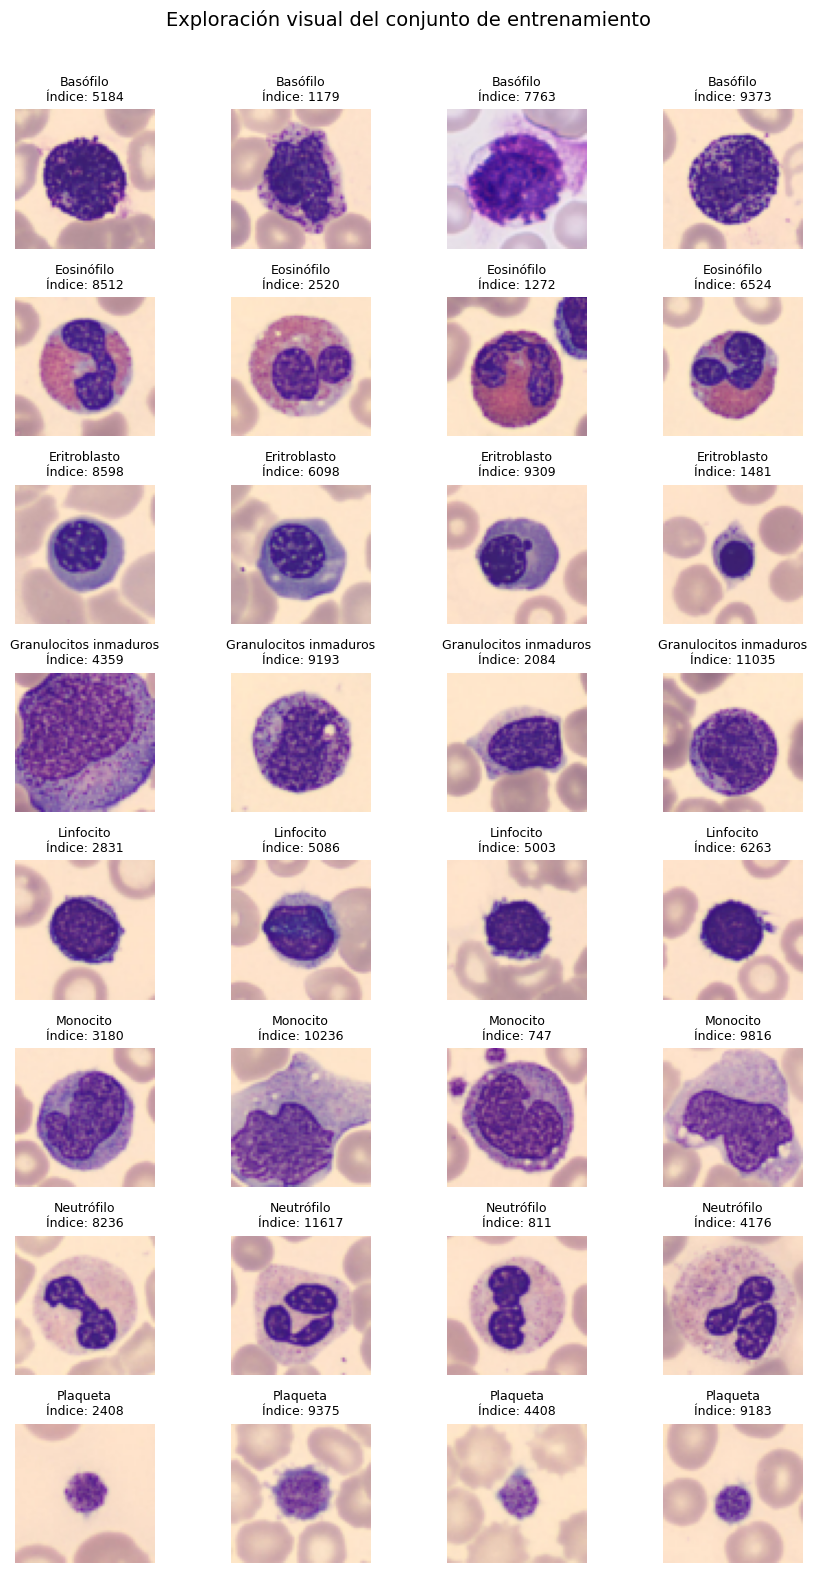

In [ ]:
# Semilla para obtener los mismos ejemplos
# cada vez que se ejecute la celda
rng = np.random.default_rng(42)

# Crear una figura con cuatro imágenes por categoría
fig, axes = plt.subplots(
    8,
    4,
    figsize=(9, 16)
)

# Recorrer las ocho categorías
for clase_id, nombre in enumerate(nombres_clases):

    # Localizar las imágenes de la categoría
    indices = np.where(
        y_train.ravel() == clase_id
    )[0]

    # Seleccionar cuatro imágenes sin repetir
    seleccion = rng.choice(
        indices,
        size=4,
        replace=False
    )

    # Mostrar las imágenes seleccionadas
    for columna, indice in enumerate(seleccion):
        ax = axes[clase_id, columna]

        ax.imshow(
            X_train[indice]
        )

        ax.set_title(
            f"{nombre}\nÍndice: {indice}",
            fontsize=9
        )

        ax.axis("off")

plt.suptitle(
    "Exploración visual del conjunto de entrenamiento",
    fontsize=14
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

#### Interpretación

La visualización permitió comprobar que las imágenes se representan correctamente y observar variaciones dentro de una misma categoría en la forma, la tinción y la posición de las células. La resolución de 64 × 64 píxeles permite reconocer características generales, aunque limita la observación de detalles morfológicos finos.

## 5. Detección de imágenes duplicadas

Se analizará la presencia de imágenes duplicadas dentro de cada conjunto y compartidas entre entrenamiento, validación y prueba. También se verificará si las imágenes repetidas conservan la misma etiqueta. Este control permitirá detectar posibles fugas de información y evitar que una misma imagen participe tanto en el entrenamiento como en la evaluación del modelo.

In [ ]:
import hashlib
from collections import Counter

# Generar una huella digital según los píxeles de cada imagen
def obtener_huellas(imagenes):
    return [
        hashlib.sha256(
            np.ascontiguousarray(imagen).tobytes()
        ).hexdigest()
        for imagen in imagenes
    ]

# Reunir los tres conjuntos originales
conjuntos = {
    "Entrenamiento": (X_train, y_train),
    "Validación": (X_val, y_val),
    "Prueba": (X_test, y_test)
}

huellas = {}
resumen = []
etiquetas_por_huella = {}

# Buscar duplicados dentro de cada conjunto
for nombre, (imagenes, etiquetas) in conjuntos.items():
    huellas[nombre] = obtener_huellas(imagenes)
    conteos = Counter(huellas[nombre])

    resumen.append({
        "Conjunto": nombre,
        "Imágenes": len(imagenes),
        "Imágenes únicas": len(conteos),
        "Copias adicionales": len(imagenes) - len(conteos)
    })

    # Registrar las etiquetas asociadas a cada imagen
    for huella, etiqueta in zip(
        huellas[nombre],
        etiquetas.ravel()
    ):
        etiquetas_por_huella.setdefault(
            huella,
            set()
        ).add(int(etiqueta))

print("DUPLICADOS DENTRO DE CADA CONJUNTO")
display(pd.DataFrame(resumen))

# Comparar duplicados entre conjuntos
comparaciones = [
    ("Entrenamiento", "Validación"),
    ("Entrenamiento", "Prueba"),
    ("Validación", "Prueba")
]

cruces = []

for conjunto_a, conjunto_b in comparaciones:
    compartidas = (
        set(huellas[conjunto_a])
        & set(huellas[conjunto_b])
    )

    cruces.append({
        "Comparación": f"{conjunto_a} / {conjunto_b}",
        "Imágenes únicas compartidas": len(compartidas)
    })

print("\nDUPLICADOS ENTRE CONJUNTOS")
display(pd.DataFrame(cruces))

# Contar imágenes iguales asociadas a etiquetas diferentes
conflictos = sum(
    len(etiquetas) > 1
    for etiquetas in etiquetas_por_huella.values()
)

print(
    "\nImágenes únicas con etiquetas contradictorias:",
    conflictos
)

DUPLICADOS DENTRO DE CADA CONJUNTO


,Conjunto,Imágenes,Imágenes únicas,Copias adicionales
0,Entrenamiento,11959,11951,8
1,Validación,1712,1712,0
2,Prueba,3421,3421,0



DUPLICADOS ENTRE CONJUNTOS


,Comparación,Imágenes únicas compartidas
0,Entrenamiento / Validación,3
1,Entrenamiento / Prueba,5
2,Validación / Prueba,1



Imágenes únicas con etiquetas contradictorias: 1


#### Interpretación

Se detectaron ocho copias adicionales dentro del conjunto de entrenamiento. Además, se encontraron imágenes compartidas entre entrenamiento, validación y prueba, lo que podría producir una fuga de información y generar una evaluación demasiado optimista del modelo.

También se identificó una imagen asociada a etiquetas diferentes. Por lo tanto, será necesario revisar estos casos y definir un criterio de depuración antes de preparar los datos para el entrenamiento.

## 6. Gestión y depuración de imágenes duplicadas

A partir de los duplicados identificados, se documentarán sus ubicaciones y etiquetas, se establecerá un criterio de limpieza y se generarán conjuntos depurados. Finalmente, se verificará que no permanezcan imágenes repetidas dentro de los conjuntos ni compartidas entre entrenamiento, validación y prueba.

### 6.1. Detalle y Origen de las Imágenes Duplicadas

Para documentar los casos detectados, identificaré en qué conjunto e índice aparece cada imagen repetida y qué categoría tiene asignada. Esto permitirá reconocer posibles contradicciones en las etiquetas y definir posteriormente un criterio de depuración trazable.

In [ ]:
from collections import defaultdict

# Registrar dónde aparece cada imagen repetida
apariciones = defaultdict(list)

for nombre, (_, etiquetas) in conjuntos.items():
    for indice, (huella, etiqueta) in enumerate(
        zip(huellas[nombre], etiquetas.ravel())
    ):
        etiqueta = int(etiqueta)

        apariciones[huella].append({
            "Conjunto": nombre,
            "Índice": indice,
            "Etiqueta": etiqueta,
            "Clase": nombres_clases[etiqueta]
        })

# Reunir las apariciones de imágenes repetidas
filas = []
grupo = 0

for registros in apariciones.values():
    if len(registros) > 1:
        grupo += 1

        # Verificar si la misma imagen tiene etiquetas diferentes
        conflicto = (
            len({
                registro["Etiqueta"]
                for registro in registros
            }) > 1
        )

        for registro in registros:
            filas.append({
                "Grupo duplicado": grupo,
                **registro,
                "Etiquetas contradictorias": conflicto
            })

# Crear una tabla con los casos identificados
detalle_duplicados = pd.DataFrame(filas)

print("Detalle de imágenes repetidas:")
display(detalle_duplicados)

print("\nCasos con etiquetas contradictorias:")
display(
    detalle_duplicados[
        detalle_duplicados["Etiquetas contradictorias"]
    ]
)

Detalle de imágenes repetidas:


,Grupo duplicado,Conjunto,Índice,Etiqueta,Clase,Etiquetas contradictorias
0,1,Entrenamiento,120,3,Granulocitos inmaduros,False
1,1,Entrenamiento,4761,3,Granulocitos inmaduros,False
2,2,Entrenamiento,810,0,Basófilo,False
3,2,Entrenamiento,11026,0,Basófilo,False
4,3,Entrenamiento,1018,1,Eosinófilo,True
5,3,Prueba,3126,6,Neutrófilo,True
6,4,Entrenamiento,1074,1,Eosinófilo,False
7,4,Entrenamiento,3440,1,Eosinófilo,False
8,5,Entrenamiento,2835,1,Eosinófilo,False
9,5,Validación,896,1,Eosinófilo,False



Casos con etiquetas contradictorias:


,Grupo duplicado,Conjunto,Índice,Etiqueta,Clase,Etiquetas contradictorias
4,3,Entrenamiento,1018,1,Eosinófilo,True
5,3,Prueba,3126,6,Neutrófilo,True


#### Interpretación

Se identificaron 17 imágenes diferentes que aparecen repetidas, con dos apariciones cada una. Ocho están duplicadas dentro del conjunto de entrenamiento y nueve se encuentran compartidas entre distintos conjuntos.

En 16 casos, las dos copias tienen asignada la misma categoría. En el caso restante, una misma imagen figura como eosinófilo en entrenamiento y como neutrófilo en prueba, lo que evidencia una contradicción en el etiquetado.

### 6.2. Criterio de limpieza

A partir de los casos identificados, aplicaré los siguientes criterios:

- Excluiré las dos apariciones de la imagen con etiquetas contradictorias, ya que no es posible determinar cuál categoría es correcta.

- En los duplicados internos del conjunto de entrenamiento, conservaré una sola copia.

- En las imágenes compartidas entre entrenamiento y validación, conservaré la copia de validación.

- En las imágenes presentes en prueba y en otro conjunto, conservaré la copia de prueba y excluiré las restantes.

Los datos originales se mantendrán sin modificaciones y todas las exclusiones quedarán registradas para asegurar la trazabilidad.

Después de la depuración, verificaré nuevamente la ausencia de duplicados y prepararé los conjuntos resultantes para los modelos.

Este procedimiento modificará ligeramente las particiones originales de BloodMNIST. Los mismos conjuntos depurados se utilizarán para entrenar y evaluar todos los modelos bajo las mismas condiciones.

### 6.3. Aplicación del criterio de depuración

Aplicaré mediante código los criterios definidos anteriormente para generar los conjuntos depurados de entrenamiento, validación y prueba. También crearé un registro con las imágenes excluidas y el motivo correspondiente.

In [ ]:
import hashlib
import pandas as pd
import numpy as np

# Función para identificar cada imagen mediante su contenido
def calcular_hash(imagen):
    return hashlib.sha256(imagen.tobytes()).hexdigest()

# Calcular los hashes de los conjuntos originales
hash_train = np.array([calcular_hash(img) for img in X_train])
hash_val = np.array([calcular_hash(img) for img in X_val])
hash_test = np.array([calcular_hash(img) for img in X_test])

# Máscaras inicialmente completas
mantener_train = np.ones(len(X_train), dtype=bool)
mantener_val = np.ones(len(X_val), dtype=bool)
mantener_test = np.ones(len(X_test), dtype=bool)

# Registro de las exclusiones realizadas
registro_exclusiones = []

def registrar_exclusion(conjunto, indice, etiqueta, motivo):
    etiqueta = int(np.asarray(etiqueta).squeeze())

    registro_exclusiones.append({
        "Conjunto": conjunto,
        "Índice original": indice,
        "Etiqueta": etiqueta,
        "Clase": clases[str(etiqueta)],
        "Motivo de exclusión": motivo
    })

# 1. Excluir ambas apariciones del caso contradictorio
mantener_train[1018] = False
registrar_exclusion(
    "Entrenamiento",
    1018,
    y_train[1018],
    "Imagen con etiqueta contradictoria respecto del conjunto de prueba"
)

mantener_test[3126] = False
registrar_exclusion(
    "Prueba",
    3126,
    y_test[3126],
    "Imagen con etiqueta contradictoria respecto del conjunto de entrenamiento"
)

# 2. Prioridad prueba > validación:
# retirar de validación las imágenes que también permanecen en prueba
hashes_test_conservados = set(hash_test[mantener_test])

for indice in np.where(mantener_val)[0]:
    if hash_val[indice] in hashes_test_conservados:
        mantener_val[indice] = False
        registrar_exclusion(
            "Validación",
            indice,
            y_val[indice],
            "Imagen repetida en prueba; se conserva la copia de prueba"
        )

# 3. Prioridad prueba > validación > entrenamiento:
# retirar de entrenamiento las imágenes presentes en prueba o validación
hashes_val_conservados = set(hash_val[mantener_val])

for indice in np.where(mantener_train)[0]:
    if hash_train[indice] in hashes_test_conservados:
        mantener_train[indice] = False
        registrar_exclusion(
            "Entrenamiento",
            indice,
            y_train[indice],
            "Imagen repetida en prueba; se conserva la copia de prueba"
        )

    elif hash_train[indice] in hashes_val_conservados:
        mantener_train[indice] = False
        registrar_exclusion(
            "Entrenamiento",
            indice,
            y_train[indice],
            "Imagen repetida en validación; se conserva la copia de validación"
        )

# 4. Conservar una sola copia de los duplicados internos de entrenamiento
hashes_observados = set()

for indice in np.where(mantener_train)[0]:
    if hash_train[indice] in hashes_observados:
        mantener_train[indice] = False
        registrar_exclusion(
            "Entrenamiento",
            indice,
            y_train[indice],
            "Copia adicional de un duplicado interno de entrenamiento"
        )
    else:
        hashes_observados.add(hash_train[indice])

# Crear los conjuntos depurados sin sobrescribir los originales
X_train_clean = X_train[mantener_train]
y_train_clean = y_train[mantener_train]

X_val_clean = X_val[mantener_val]
y_val_clean = y_val[mantener_val]

X_test_clean = X_test[mantener_test]
y_test_clean = y_test[mantener_test]

# Convertir el registro en una tabla
registro_exclusiones = pd.DataFrame(registro_exclusiones)

print("Dimensiones antes y después de la depuración:\n")

print(f"Entrenamiento: {len(X_train)} → {len(X_train_clean)}")
print(f"Validación:    {len(X_val)} → {len(X_val_clean)}")
print(f"Prueba:        {len(X_test)} → {len(X_test_clean)}")

print(f"\nTotal de imágenes excluidas: {len(registro_exclusiones)}")

registro_exclusiones

Dimensiones antes y después de la depuración:

Entrenamiento: 11959 → 11943
Validación:    1712 → 1711
Prueba:        3421 → 3420

Total de imágenes excluidas: 18


,Conjunto,Índice original,Etiqueta,Clase,Motivo de exclusión
0,Entrenamiento,1018,1,eosinophil,Imagen con etiqueta contradictoria respecto de...
1,Prueba,3126,6,neutrophil,Imagen con etiqueta contradictoria respecto de...
2,Validación,1593,1,eosinophil,Imagen repetida en prueba; se conserva la copi...
3,Entrenamiento,2835,1,eosinophil,Imagen repetida en validación; se conserva la ...
4,Entrenamiento,4375,0,basophil,Imagen repetida en prueba; se conserva la copi...
5,Entrenamiento,4995,0,basophil,Imagen repetida en prueba; se conserva la copi...
6,Entrenamiento,7646,1,eosinophil,Imagen repetida en prueba; se conserva la copi...
7,Entrenamiento,8530,1,eosinophil,Imagen repetida en validación; se conserva la ...
8,Entrenamiento,10505,0,basophil,Imagen repetida en prueba; se conserva la copi...
9,Entrenamiento,11443,0,basophil,Imagen repetida en validación; se conserva la ...


#### Interpretación

Se excluyeron 18 imágenes: 16 de entrenamiento, una de validación y una de prueba. Aunque se identificaron 17 grupos repetidos, el total es mayor porque se eliminaron las dos apariciones del caso con etiquetas contradictorias. Todas las exclusiones quedaron registradas con su correspondiente motivo.

### 6.4. Verificación de los conjuntos depurados

Verificaré que los conjuntos depurados no contengan duplicados internos ni imágenes compartidas entre entrenamiento, validación y prueba. Este control permitirá confirmar la independencia de las particiones utilizadas por los modelos.

In [ ]:
# Calcular los hashes de los conjuntos depurados
hash_train_clean = np.array(
    [calcular_hash(img) for img in X_train_clean]
)

hash_val_clean = np.array(
    [calcular_hash(img) for img in X_val_clean]
)

hash_test_clean = np.array(
    [calcular_hash(img) for img in X_test_clean]
)

# Duplicados internos
duplicados_train_clean = (
    len(hash_train_clean) - len(set(hash_train_clean))
)

duplicados_val_clean = (
    len(hash_val_clean) - len(set(hash_val_clean))
)

duplicados_test_clean = (
    len(hash_test_clean) - len(set(hash_test_clean))
)

# Coincidencias entre conjuntos
coincidencias_train_val = (
    set(hash_train_clean) & set(hash_val_clean)
)

coincidencias_train_test = (
    set(hash_train_clean) & set(hash_test_clean)
)

coincidencias_val_test = (
    set(hash_val_clean) & set(hash_test_clean)
)

print("Duplicados internos después de la depuración:")
print(f"Entrenamiento: {duplicados_train_clean}")
print(f"Validación:    {duplicados_val_clean}")
print(f"Prueba:        {duplicados_test_clean}")

print("\nCoincidencias entre conjuntos:")
print(f"Entrenamiento–Validación: {len(coincidencias_train_val)}")
print(f"Entrenamiento–Prueba:     {len(coincidencias_train_test)}")
print(f"Validación–Prueba:        {len(coincidencias_val_test)}")

Duplicados internos después de la depuración:
Entrenamiento: 0
Validación:    0
Prueba:        0

Coincidencias entre conjuntos:
Entrenamiento–Validación: 0
Entrenamiento–Prueba:     0
Validación–Prueba:        0


#### Interpretación

La verificación confirmó que los conjuntos depurados no contienen duplicados internos ni imágenes compartidas entre entrenamiento, validación y prueba. Esto reduce el riesgo de fuga de información y permite realizar la evaluación con particiones independientes.

## 7. Preparación final de los datos depurados



### 7.1. Normalización para la CNN propia

Para preparar los datos de entrada de la CNN propia, convertiré las imágenes depuradas a tipo decimal y escalaré los valores de los píxeles al intervalo de 0 a 1.

Las etiquetas se convertirán en vectores unidimensionales, manteniendo su codificación numérica original. Los conjuntos resultantes se utilizarán para entrenar, validar y evaluar la CNN.

In [ ]:
# Normalizar las imágenes depuradas para la CNN propia
X_train_cnn = X_train_clean.astype("float32") / 255.0
X_val_cnn = X_val_clean.astype("float32") / 255.0
X_test_cnn = X_test_clean.astype("float32") / 255.0

# Convertir las etiquetas en vectores unidimensionales
y_train_cnn = y_train_clean.ravel()
y_val_cnn = y_val_clean.ravel()
y_test_cnn = y_test_clean.ravel()

# Verificar las dimensiones finales
print("Dimensiones de los conjuntos preparados:")
print("Entrenamiento:", X_train_cnn.shape, y_train_cnn.shape)
print("Validación:   ", X_val_cnn.shape, y_val_cnn.shape)
print("Prueba:       ", X_test_cnn.shape, y_test_cnn.shape)

# Verificar el rango de los píxeles en los tres conjuntos
print("\nRango de píxeles:")
print(
    f"Entrenamiento: {X_train_cnn.min():.4f} – "
    f"{X_train_cnn.max():.4f}"
)
print(
    f"Validación:    {X_val_cnn.min():.4f} – "
    f"{X_val_cnn.max():.4f}"
)
print(
    f"Prueba:        {X_test_cnn.min():.4f} – "
    f"{X_test_cnn.max():.4f}"
)

# Verificar los tipos de datos
print("\nTipos de datos:")
print("Imágenes:", X_train_cnn.dtype)
print("Etiquetas:", y_train_cnn.dtype)

Dimensiones de los conjuntos preparados:
Entrenamiento: (11943, 64, 64, 3) (11943,)
Validación:    (1711, 64, 64, 3) (1711,)
Prueba:        (3420, 64, 64, 3) (3420,)

Rango de píxeles:
Entrenamiento: 0.0314 – 1.0000
Validación:    0.0353 – 1.0000
Prueba:        0.0353 – 1.0000

Tipos de datos:
Imágenes: float32
Etiquetas: uint8


#### Interpretación

Los conjuntos depurados quedaron preparados para la CNN propia. Las imágenes conservan sus dimensiones de 64 × 64 píxeles y tres canales de color, y cada imagen mantiene su etiqueta correspondiente.

Los píxeles se convirtieron a float32 y quedaron normalizados en un rango aproximado de 0,03 a 1. Las etiquetas se organizaron como vectores unidimensionales y conservaron su codificación numérica original.

### 7.2. Elección de la métrica principal

Considerando el objetivo multiclase planteado, no existe una única categoría positiva ni se prioriza globalmente un tipo de error sobre otro. Para cada categoría, un falso positivo implica clasificar incorrectamente otra imagen como perteneciente a ella, mientras que un falso negativo representa no reconocer una imagen que realmente corresponde a esa categoría.

Por este motivo, y debido al desbalance observado entre las categorías, utilizaré el **F1 macro** como **métrica principal** para evaluar, seleccionar y comparar los modelos. Esta métrica combina precisión y recall, calcula el desempeño de cada categoría por separado y asigna la misma importancia a las ocho clases, independientemente de la cantidad de imágenes que contenga cada una.

La **precisión** y el **recall por clase** se utilizarán como **métricas auxiliares** para identificar en qué categorías predominan los falsos positivos o los falsos negativos. La **matriz de confusión** y las **imágenes mal clasificadas** permitirán interpretar la **naturaleza de esos errores.**

## 8. Desarrollo de la CNN propia

### 8.1. Definición de la arquitectura

Desarrollaré una red neuronal convolucional propia para clasificar las imágenes en las ocho categorías de BloodMNIST.

La red estará formada por tres bloques convolucionales. Las primeras capas buscarán características visuales simples, como bordes, colores y texturas, mientras que las capas más profundas podrán combinar esa información para reconocer patrones más complejos relacionados con la morfología celular.

Después de la extracción de características, una capa densa realizará la clasificación. La capa de salida tendrá ocho neuronas, una por categoría, y utilizará la función de activación `softmax` para obtener una probabilidad para cada clase.

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Semilla para favorecer la reproducibilidad
tf.keras.utils.set_random_seed(42)

modelo_cnn = Sequential([
    Input(shape=(64, 64, 3)),

    # Primer bloque convolucional
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Segundo bloque convolucional
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Tercer bloque convolucional
    Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Clasificación
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(8, activation="softmax")
])

modelo_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,984 (4.36 MB)

 Trainable params: 1,142,984 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

#### Esquema visual de la arquitectura

El siguiente esquema representa las capas que componen la CNN propia y las dimensiones de sus respectivas salidas.


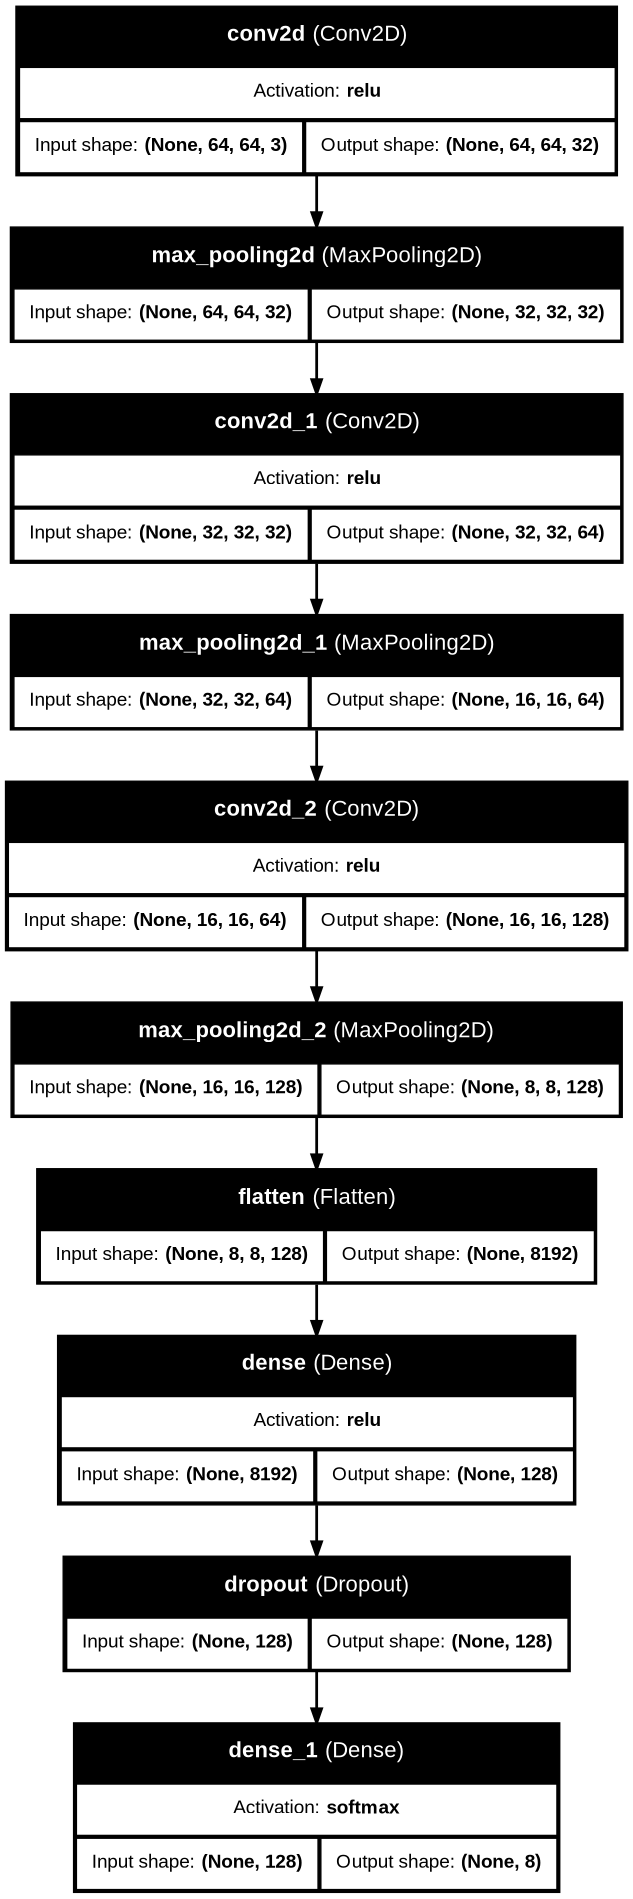

In [ ]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

# Ruta para guardar el esquema
ruta_esquema_cnn = (
    carpeta_proyecto /
    "arquitectura_cnn_propia.png"
)

# Generar el esquema de la CNN
plot_model(
    modelo_cnn,
    to_file=str(ruta_esquema_cnn),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    rankdir="TB",
    dpi=100
)

# Mostrar el esquema en el notebook
display(
    Image(filename=str(ruta_esquema_cnn))
)

#### Interpretación de la arquitectura

La red reduce progresivamente las imágenes desde 64 × 64 hasta mapas de características de 8 × 8, mientras aumenta la cantidad de filtros de 32 a 128. Luego, **Flatten** transforma esos mapas en un vector de 8.192 valores.

La **capa densa** tiene 128 neuronas y concentra 1.048.704 parámetros entrenables, correspondientes a la mayor parte de los parámetros del modelo. **Dropout** desactiva aleatoriamente el 50 % de sus unidades durante el entrenamiento para reducir el riesgo de sobreajuste. Finalmente, la **capa de salida** genera una probabilidad para cada una de las ocho categorías.

### 8.2. Compilación del modelo

Para entrenar la CNN utilizaré el **optimizador Adam**, con una tasa de aprendizaje de 0,001, y la **función de pérdida** **sparse_categorical_crossentropy**, adecuada para una clasificación multiclase con etiquetas enteras.

La **función de pérdida** permitirá ajustar los parámetros del modelo. La **exactitud calculada por Keras** se utilizará únicamente como **información descriptiva** durante el entrenamiento y para construir las **curvas de aprendizaje**.

In [ ]:
# Compilar la CNN propia
modelo_cnn.compile(

    # Adam actualizará los parámetros para reducir la pérdida
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Función de pérdida para clasificación multiclase
    # con etiquetas enteras codificadas del 0 al 7
    loss="sparse_categorical_crossentropy",

    # Se registra únicamente para describir la evolución
    # del entrenamiento y construir las curvas de aprendizaje
    metrics=["accuracy"]
)

print("Modelo compilado correctamente.")

Modelo compilado correctamente.


### 8.3. Entrenamiento de la CNN propia

Entrenaré la CNN utilizando los conjuntos depurados y normalizados, con un máximo de 30 épocas y lotes de 32 imágenes.

Para controlar el sobreajuste, utilizaré **EarlyStopping**, que detendrá el entrenamiento si la pérdida de validación no mejora durante ocho épocas consecutivas. También utilizaré **ModelCheckpoint** para guardar la versión del modelo que alcance la menor pérdida de validación.


#### 8.3.1. Configuración de callbacks

In [ ]:
# Ruta donde se guardará el mejor modelo de la CNN
ruta_modelo_cnn = carpeta_proyecto / "mejor_modelo_cnn.keras"

# Detener el entrenamiento si la pérdida de validación
# no mejora durante ocho épocas consecutivas
early_stopping_cnn = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

# Guardar únicamente el modelo con la menor pérdida de validación
checkpoint_cnn = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(ruta_modelo_cnn),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Agrupar los callbacks para utilizarlos durante el entrenamiento
callbacks_cnn = [
    early_stopping_cnn,
    checkpoint_cnn
]

print("Callbacks configurados correctamente.")
print("El mejor modelo se guardará en:", ruta_modelo_cnn)

Callbacks configurados correctamente.
El mejor modelo se guardará en: /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_cnn.keras


#### 8.3.2. Ejecución del entrenamiento

En este punto se entrena la CNN con el conjunto de entrenamiento y se controla su desempeño durante el proceso mediante el conjunto de validación.

In [ ]:
# Entrenar la CNN propia
historial_cnn = modelo_cnn.fit(
    # Datos utilizados para ajustar los parámetros del modelo
    X_train_cnn,
    y_train_cnn,

    # Datos utilizados para controlar el desempeño durante el entrenamiento
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),

    # Cantidad máxima de épocas y tamaño de cada lote
    epochs=30,
    batch_size=32,

    # Callbacks configurados en el punto anterior
    callbacks=callbacks_cnn,

    # Mostrar el progreso de cada época
    verbose=1
)

Epoch 1/30
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4323 - loss: 1.4734
Epoch 1: val_loss improved from None to 0.49254, saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_cnn.keras
374/374 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.5799 - loss: 1.0993 - val_accuracy: 0.8025 - val_loss: 0.4925
Epoch 2/30
371/374 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7483 - loss: 0.6509
Epoch 2: val_loss improved from 0.49254 to 0.41165, saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_cnn.keras
374/374 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7642 - loss: 0.6331 - val_accuracy: 0.8469 - val_loss: 0.4116
Epoch 3/30
372/374 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7997 - loss: 0.5188
Epoch 3: val_loss improved from 0.41165 to 0.33275, saving

#### Interpretación del entrenamiento

El entrenamiento se detuvo en la **época 23** porque la pérdida de validación no mejoró durante ocho épocas consecutivas. El menor valor de pérdida de validación se obtuvo en la **época 15**, con aproximadamente 0,1099, por lo que se recuperaron automáticamente los pesos correspondientes a esa época.

Este comportamiento indica que continuar entrenando no estaba mejorando la capacidad de generalización del modelo y podía aumentar el riesgo de sobreajuste.

### 8.4. Curvas de aprendizaje

En este apartado se representará la **evolución de la pérdida** y de la **exactitud** en los conjuntos de **entrenamiento** y **validación**. Estas curvas permiten observar el comportamiento de la CNN durante las épocas ejecutadas y detectar posibles diferencias entre ambos conjuntos.

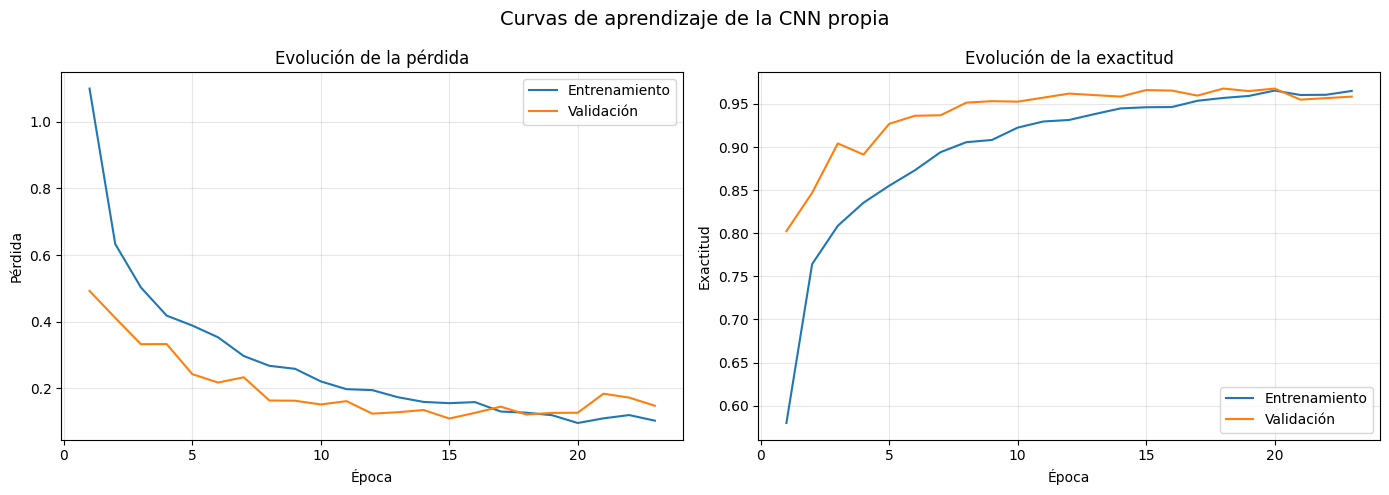

In [ ]:
# Obtener el número de épocas ejecutadas
epocas_cnn = range(
    1,
    len(historial_cnn.history["loss"]) + 1
)

# Crear una figura con dos gráficos
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Gráfico de la pérdida
axes[0].plot(
    epocas_cnn,
    historial_cnn.history["loss"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas_cnn,
    historial_cnn.history["val_loss"],
    label="Validación"
)

axes[0].set_title("Evolución de la pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfico de la exactitud
axes[1].plot(
    epocas_cnn,
    historial_cnn.history["accuracy"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas_cnn,
    historial_cnn.history["val_accuracy"],
    label="Validación"
)

axes[1].set_title("Evolución de la exactitud")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Exactitud")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Curvas de aprendizaje de la CNN propia",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Interpretación

Las curvas muestran que la pérdida disminuye y la exactitud aumenta en ambos conjuntos durante las primeras épocas, lo que indica que la CNN aprendió progresivamente a clasificar las imágenes.

A partir de aproximadamente la época 15, la pérdida de validación deja de mejorar y presenta pequeñas oscilaciones, mientras que la pérdida de entrenamiento continúa descendiendo. Esto coincide con la época seleccionada por los callbacks como la de menor pérdida de validación.

Durante la mayor parte del entrenamiento, la exactitud de validación fue superior a la de entrenamiento. Este comportamiento puede relacionarse con el uso de **Dropout**, que desactiva aleatoriamente neuronas solo durante el entrenamiento. En las últimas épocas ambas curvas se igualan, lo que coincide con el momento en que el modelo deja de mejorar su capacidad de generalización.

### 8.5. Evaluación global sobre el conjunto de prueba

Se evaluará la CNN sobre el conjunto de prueba, que no fue utilizado durante el entrenamiento ni en la selección de los mejores pesos. Se calcularán la pérdida y el F1 macro.

In [ ]:
# Evaluar el modelo sobre el conjunto de prueba
test_loss_cnn, _ = modelo_cnn.evaluate(
    X_test_cnn,
    y_test_cnn,
    verbose=1
)

# Obtener las probabilidades predichas
probabilidades_cnn = modelo_cnn.predict(
    X_test_cnn,
    verbose=0
)

# Obtener la categoría con mayor probabilidad
y_pred_cnn = np.argmax(
    probabilidades_cnn,
    axis=1
)

# Calcular el F1 macro
f1_macro_cnn = f1_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro"
)

print(f"\nPérdida en prueba: {test_loss_cnn:.4f}")
print(f"F1 macro de la CNN propia: {f1_macro_cnn:.4f}")

107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9611 - loss: 0.1324

Pérdida en prueba: 0.1324
F1 macro de la CNN propia: 0.9562


#### Interpretación de la evaluación global

La CNN obtuvo una **pérdida** de 0,1324 y un **F1 macro** de 0,9562 sobre el conjunto de prueba. El valor del F1 macro, cercano a 1, indica un desempeño global alto, considerando con la misma importancia las ocho categorías celulares y el equilibrio entre precisión y recall.

### 8.6. Evaluación del desempeño por clase

Para analizar el comportamiento de la CNN en cada categoría, se calcularán la **precisión** y el **recall por clase**. Estas métricas permitirán identificar en qué categorías predominan los falsos positivos o los falsos negativos.

In [ ]:
# Calcular la precisión de cada categoría
precision_por_clase_cnn = precision_score(
    y_test_cnn,
    y_pred_cnn,
    labels=range(8),
    average=None,
    zero_division=0
)

# Calcular el recall de cada categoría
recall_por_clase_cnn = recall_score(
    y_test_cnn,
    y_pred_cnn,
    labels=range(8),
    average=None,
    zero_division=0
)

# Contar la cantidad de imágenes reales de cada categoría
cantidad_por_clase_cnn = np.bincount(
    y_test_cnn,
    minlength=8
)

# Organizar los resultados en una tabla
desempeno_por_clase_cnn = pd.DataFrame({
    "Categoría": nombres_clases,
    "Precisión": precision_por_clase_cnn,
    "Recall": recall_por_clase_cnn,
    "Cantidad de imágenes": cantidad_por_clase_cnn
})

# Mostrar las métricas con cuatro decimales
display(
    desempeno_por_clase_cnn.style.format({
        "Precisión": "{:.4f}",
        "Recall": "{:.4f}"
    })
)

,Categoría,Precisión,Recall,Cantidad de imágenes
0,Basófilo,0.9738,0.9139,244
1,Eosinófilo,0.9984,0.9952,624
2,Eritroblasto,0.9669,0.9389,311
3,Granulocitos inmaduros,0.8975,0.9378,579
4,Linfocito,0.9409,0.9835,243
5,Monocito,0.9267,0.8908,284
6,Neutrófilo,0.9731,0.9789,665
7,Plaqueta,0.9979,0.9894,470


#### Interpretación del desempeño por clase

El desempeño fue alto en las ocho categorías, aunque no fue uniforme. Los eosinófilos y las plaquetas presentaron los valores más elevados de precisión y recall, superiores a 0,98 en ambos casos, por lo que fueron las categorías mejor reconocidas.

Las principales dificultades se observaron en los granulocitos inmaduros y los monocitos. Los granulocitos inmaduros tuvieron la menor **precisión** (0,8975), lo que indica una mayor presencia de falsos positivos. Los monocitos presentaron el menor **recall** (0,8908), por lo que fueron la categoría con mayor proporción de casos reales no reconocidos correctamente.

Los basófilos mostraron el patrón inverso al de los granulocitos inmaduros: una precisión elevada (0,9738) pero un recall menor (0,9139). Cuando la CNN predijo "basófilo" casi siempre acertó, pero no reconoció una parte de los basófilos reales. Los linfocitos, en cambio, tuvieron un recall muy alto (0,9835) con una precisión algo menor (0,9409), porque algunas células de otras categorías fueron clasificadas como linfocitos.

### 8.7. Matriz de confusión

La matriz de confusión permitirá observar la distribución de los aciertos y errores de la CNN entre las ocho categorías celulares. Las filas representan las categorías verdaderas y las columnas, las categorías predichas.

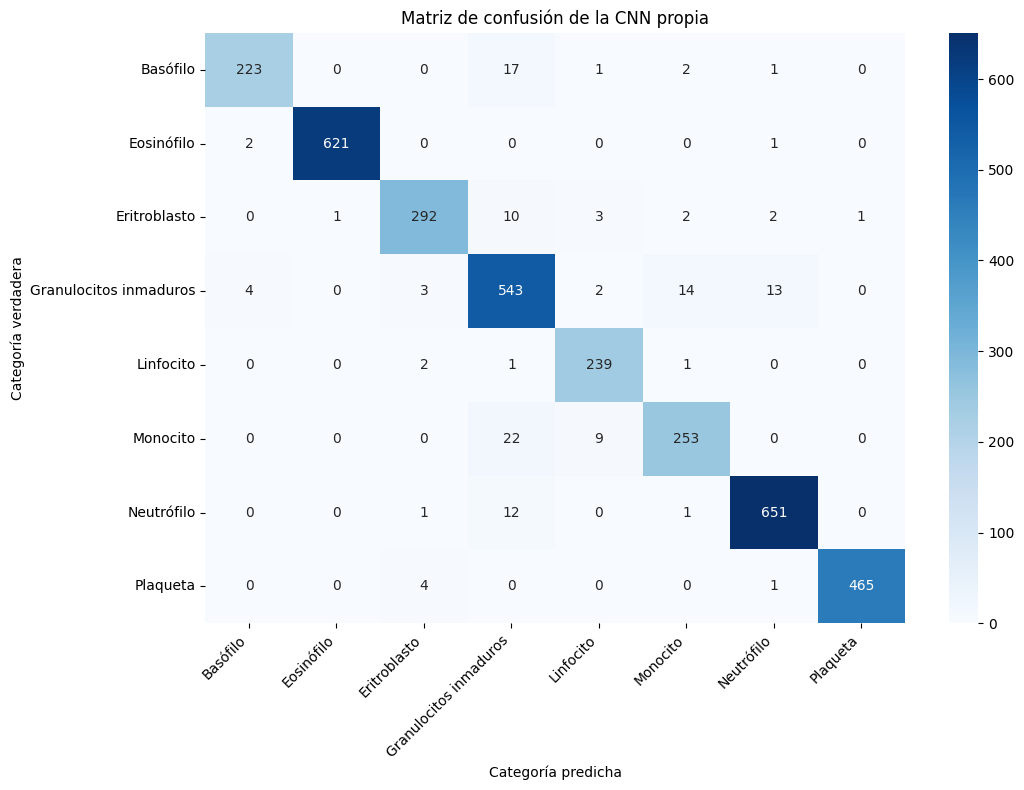

In [ ]:
# Calcular la matriz de confusión
matriz_cnn = confusion_matrix(
    y_test_cnn,
    y_pred_cnn,
    labels=range(8)
)

# Crear la figura
plt.figure(figsize=(11, 8))

# Representar la matriz como mapa de calor
sns.heatmap(
    matriz_cnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

# Agregar títulos y nombres de los ejes
plt.title("Matriz de confusión de la CNN propia")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría verdadera")

# Ajustar la orientación de las etiquetas
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#### Interpretación de la matriz de confusión

La CNN clasificó correctamente 3.287 de las 3.420 imágenes del conjunto de prueba y cometió 133 errores. La concentración de los resultados en la diagonal principal muestra que la mayoría de las imágenes fue asignada a su categoría correspondiente.

Los granulocitos inmaduros fueron la principal categoría receptora de errores: 22 monocitos, 17 basófilos, 12 neutrófilos y 10 eritroblastos fueron clasificados dentro de esta categoría. A su vez, 14 granulocitos inmaduros fueron identificados como monocitos y 13 como neutrófilos. También se observaron 9 monocitos clasificados como linfocitos, lo que explica en parte la menor precisión de los linfocitos.

Estos resultados indican que las mayores dificultades se concentraron entre categorías que pueden compartir características de tamaño, forma nuclear y granulación. En cambio, los eosinófilos y las plaquetas fueron las categorías reconocidas con menor cantidad proporcional de errores.

### 8.8. Análisis visual de imágenes mal clasificadas

Para complementar la matriz de confusión, visualizaré nueve imágenes clasificadas incorrectamente. En cada caso se indicará la categoría verdadera, la predicción realizada por la CNN y la probabilidad asignada a esa predicción.

Total de imágenes mal clasificadas: 133


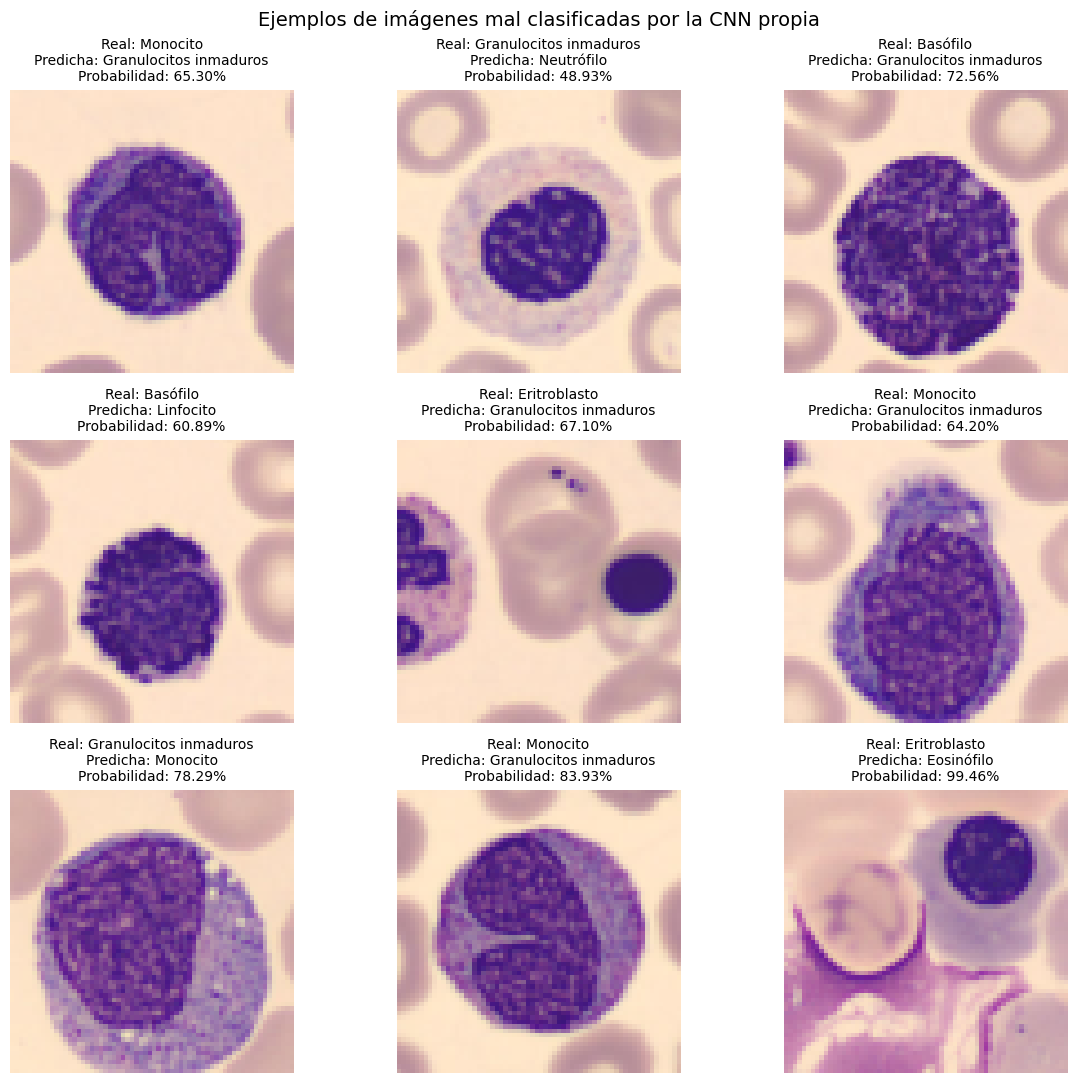

In [ ]:
# Identificar las imágenes clasificadas incorrectamente
indices_error_cnn = np.where(
    y_pred_cnn != y_test_cnn
)[0]

print(
    "Total de imágenes mal clasificadas:",
    len(indices_error_cnn)
)

# Seleccionar nueve errores de forma reproducible
rng_cnn = np.random.default_rng(42)

indices_muestra_error_cnn = rng_cnn.choice(
    indices_error_cnn,
    size=9,
    replace=False
)

# Crear una cuadrícula de tres filas por tres columnas
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 11)
)

# Mostrar cada imagen seleccionada
for ax, indice in zip(
    axes.ravel(),
    indices_muestra_error_cnn
):
    # Obtener la categoría verdadera y la predicha
    clase_real = int(y_test_cnn[indice])
    clase_predicha = int(y_pred_cnn[indice])

    # Obtener la probabilidad asignada a la predicción
    probabilidad = probabilidades_cnn[
        indice,
        clase_predicha
    ]

    # Mostrar la imagen original depurada,
    # sin la normalización aplicada para entrenar la CNN
    ax.imshow(X_test_clean[indice])

    ax.set_title(
        f"Real: {nombres_clases[clase_real]}\n"
        f"Predicha: {nombres_clases[clase_predicha]}\n"
        f"Probabilidad: {probabilidad:.2%}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Ejemplos de imágenes mal clasificadas por la CNN propia",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Interpretación de las imágenes mal clasificadas

Siete de las nueve imágenes involucran a los granulocitos inmaduros, en coincidencia con la matriz de confusión. Tres monocitos, un basófilo y un eritroblasto fueron clasificados como granulocitos inmaduros, y dos granulocitos inmaduros fueron clasificados como neutrófilo y como monocito.

En los monocitos mal clasificados se observan núcleos plegados o con una indentación marcada, una forma que también presenta el núcleo de algunos granulocitos inmaduros, como los metamielocitos. En el basófilo clasificado como granulocito inmaduro, la granulación densa cubre gran parte del núcleo, lo que dificulta distinguir su forma.

En los dos eritroblastos mal clasificados, la imagen incluye además otra célula o restos celulares en el borde del recorte. Esto sugiere que el modelo pudo basar su predicción en elementos que no corresponden a la célula principal. En uno de estos casos, el eritroblasto fue clasificado como eosinófilo con una probabilidad de 99,46 %, posiblemente influido por las zonas de tonalidad rosada presentes en la imagen.

Las probabilidades asignadas a las predicciones incorrectas variaron entre 48,93 % y 99,46 %. Algunos errores se produjeron con probabilidades cercanas al 50 %, lo que refleja incertidumbre, mientras que otros alcanzaron valores muy elevados. Por lo tanto, una probabilidad alta no garantiza que la clasificación sea correcta.

Estas nueve imágenes constituyen una muestra reproducible de los 133 errores totales, por lo que ilustran los tipos de confusión, pero no representan por sí solas su frecuencia general.

### 8.9. Síntesis del desempeño de la CNN propia

La CNN propia obtuvo una **pérdida** de 0,1324 y un **F1 macro** de 0,9562 sobre el conjunto de prueba, con 3.287 clasificaciones correctas y 133 errores.

El desempeño fue elevado en las ocho categorías, especialmente en eosinófilos y plaquetas. Las principales dificultades se concentraron alrededor de los granulocitos inmaduros, que recibieron errores de monocitos, basófilos, neutrófilos y eritroblastos. La inspección visual sugiere que estas confusiones podrían relacionarse con características morfológicas compartidas, con la resolución limitada de las imágenes y con la presencia de otras células en el recorte.

## 9. Modelo preentrenado mediante transferencia de aprendizaje

Como segundo enfoque utilizaré VGG16, una red convolucional desarrollada por Simonyan y Zisserman (2015), con pesos preentrenados sobre ImageNet (Deng et al., 2009). Mediante transferencia de aprendizaje se aprovecharán las características visuales aprendidas por este modelo y se incorporará un nuevo clasificador adaptado a las ocho categorías de BloodMNIST.

Aunque ImageNet no contiene específicamente imágenes hematológicas, sus capas convolucionales aprendieron a reconocer características generales como bordes, formas, colores y texturas. Para asegurar una evaluación consistente, se utilizarán los mismos conjuntos depurados empleados en la CNN propia.

### 9.1. Preprocesamiento específico para VGG16

VGG16 requiere un preprocesamiento diferente del utilizado para la CNN propia. Por este motivo, partiré de las imágenes depuradas sin normalizar, que conservan la escala original de sus píxeles.

Se aplicará la función **preprocess_input** específica de VGG16, que reorganiza los canales de color y centra sus valores según el procesamiento utilizado durante el entrenamiento con ImageNet. Las imágenes conservarán su tamaño de 64 × 64 píxeles, compatible con VGG16 al utilizarla sin su clasificador original. Las etiquetas mantendrán su codificación entera.

In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input

# Preparar las imágenes depuradas específicamente para VGG16
X_train_vgg = preprocess_input(
    X_train_clean.astype("float32").copy()
)

X_val_vgg = preprocess_input(
    X_val_clean.astype("float32").copy()
)

X_test_vgg = preprocess_input(
    X_test_clean.astype("float32").copy()
)

# Las etiquetas mantienen su codificación entera
y_train_vgg = y_train_clean.ravel()
y_val_vgg = y_val_clean.ravel()
y_test_vgg = y_test_clean.ravel()

print("Dimensiones preparadas para VGG16:")
print("Entrenamiento:", X_train_vgg.shape, y_train_vgg.shape)
print("Validación:   ", X_val_vgg.shape, y_val_vgg.shape)
print("Prueba:       ", X_test_vgg.shape, y_test_vgg.shape)

print("\nRango luego de preprocess_input:")
print(
    f"{X_train_vgg.min():.4f} – "
    f"{X_train_vgg.max():.4f}"
)

print("\nTipo de dato:", X_train_vgg.dtype)

Dimensiones preparadas para VGG16:
Entrenamiento: (11943, 64, 64, 3) (11943,)
Validación:    (1711, 64, 64, 3) (1711,)
Prueba:        (3420, 64, 64, 3) (3420,)

Rango luego de preprocess_input:
-112.6800 – 148.0610

Tipo de dato: float32


#### Interpretación

Los conjuntos preparados para VGG16 conservaron sus dimensiones y la correspondencia entre cada imagen y su etiqueta. Las imágenes fueron convertidas a float32 y mantuvieron su tamaño de 64 × 64 píxeles y tres canales.

Después de aplicar preprocess_input, los píxeles presentan valores negativos y positivos debido al centrado específico de los canales de color. Este procesamiento adapta las imágenes al formato esperado por VGG16 y es diferente de la normalización entre 0 y 1 utilizada para la CNN propia.

### 9.2. Carga de VGG16 y adaptación del clasificador

Cargaré VGG16 con los pesos aprendidos en ImageNet y sin su clasificador original. Inicialmente, las capas convolucionales permanecerán congeladas para conservar las características previamente aprendidas.

Sobre esta base agregaré un nuevo clasificador con una salida de ocho neuronas, correspondiente a las categorías de BloodMNIST. En esta primera etapa se entrenarán solamente las capas nuevas.

In [ ]:

from tensorflow.keras import Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

tf.keras.utils.set_random_seed(42)

# Cargar la base convolucional preentrenada
base_vgg = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

# Congelar las capas preentrenadas
base_vgg.trainable = False

# Construir el clasificador adaptado a BloodMNIST
entrada_vgg = tf.keras.Input(
    shape=(64, 64, 3)
)

x = base_vgg(
    entrada_vgg,
    training=False
)

x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)

salida_vgg = Dense(
    8,
    activation="softmax"
)(x)

modelo_vgg = Model(
    inputs=entrada_vgg,
    outputs=salida_vgg,
    name="VGG16_BloodMNIST"
)

modelo_vgg.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_BloodMNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,384 (56.39 MB)

 Trainable params: 66,696 (260.53 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

#### Interpretación de la arquitectura

El modelo contiene 14.781.384 parámetros. La base convolucional de VGG16 concentra 14.714.688 parámetros no entrenables, debido a que sus capas permanecerán congeladas durante esta primera etapa.

Sobre la base preentrenada se incorporó un clasificador compuesto por una capa de agrupamiento global, una capa densa de 128 neuronas, una **capa Dropout** y una **salida** de ocho neuronas. La **función softmax** permitirá obtener una probabilidad para cada categoría celular.

El nuevo clasificador contiene 66.696 parámetros entrenables. Por lo tanto, durante esta etapa solamente se actualizarán los pesos de las capas agregadas, mientras que los pesos previamente aprendidos por VGG16 permanecerán sin modificaciones.

### 9.3. Compilación del modelo VGG16

El modelo se compilará utilizando el **optimizador Adam** con una tasa de aprendizaje de 0,001. Como función de pérdida se empleará **sparse_categorical_crossentropy**, adecuada para un problema multiclase cuyas etiquetas se encuentran codificadas como valores enteros.

La exactitud se registrará únicamente para observar la evolución del entrenamiento. El **F1 macro** se calculará posteriormente sobre las predicciones del modelo y se mantendrá como métrica principal de evaluación.



In [ ]:
# Compilar el modelo VGG16
modelo_vgg.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    # La exactitud se utilizará solo para seguir el entrenamiento
    metrics=["accuracy"]
)

print("Modelo VGG16 compilado correctamente.")

Modelo VGG16 compilado correctamente.


El modelo VGG16 quedó compilado y preparado para comenzar el entrenamiento de las capas agregadas.

### 9.4. Entrenamiento del clasificador

Se entrenarán las capas agregadas al modelo VGG16 utilizando los conjuntos depurados y preparados específicamente para esta arquitectura. La base convolucional permanecerá congelada durante esta etapa.

Se establecerá un máximo de 30 épocas y un tamaño de lote de 32 imágenes. La pérdida de validación se utilizará para controlar el entrenamiento y conservar los mejores pesos.

#### 9.4.1. Configuración de callbacks

Se configurarán los callbacks encargados de detener el entrenamiento cuando la pérdida de validación deje de mejorar y de guardar la mejor versión del modelo.

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Detener el entrenamiento si val_loss no mejora
early_stopping_vgg = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Guardar el modelo con la menor pérdida de validación
ruta_modelo_vgg = (
    carpeta_proyecto / "mejor_modelo_vgg.keras"
)

model_checkpoint_vgg = ModelCheckpoint(
    filepath=str(ruta_modelo_vgg),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Callbacks configurados correctamente.")
print("El mejor modelo se guardará en:", ruta_modelo_vgg)

Callbacks configurados correctamente.
El mejor modelo se guardará en: /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg.keras


#### 9.4.2. Ejecución del entrenamiento

In [ ]:
historial_vgg = modelo_vgg.fit(
    X_train_vgg,
    y_train_vgg,
    validation_data=(
        X_val_vgg,
        y_val_vgg
    ),
    epochs=30,
    batch_size=32,
    callbacks=[
        early_stopping_vgg,
        model_checkpoint_vgg
    ],
    verbose=1
)

Epoch 1/30
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4691 - loss: 4.3345
Epoch 1: val_loss improved from None to 0.70201, saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg.keras
374/374 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.5635 - loss: 2.0372 - val_accuracy: 0.7750 - val_loss: 0.7020
Epoch 2/30
373/374 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7103 - loss: 0.8888
Epoch 2: val_loss improved from 0.70201 to 0.53896, saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg.keras
374/374 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.7211 - loss: 0.8412 - val_accuracy: 0.8212 - val_loss: 0.5390
Epoch 3/30
373/374 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7655 - loss: 0.7067
Epoch 3: val_loss improved from 0.53896 to 0.48316, sav

#### Interpretación del entrenamiento

El entrenamiento se detuvo anticipadamente en la época 26, después de ocho épocas sin mejoras en la pérdida de validación. La mejor pérdida de validación fue aproximadamente 0,3600 y se alcanzó en la época 18.

`EarlyStopping` detuvo el proceso y restauró los pesos de esa época, mientras que `ModelCheckpoint` guardó la mejor versión del modelo. Por lo tanto, los análisis posteriores se realizarán con la configuración que obtuvo la menor pérdida de validación durante el entrenamiento.

### 9.5. Curvas de aprendizaje de VGG16

A continuación, se muestran las curvas de aprendizaje del modelo VGG16.



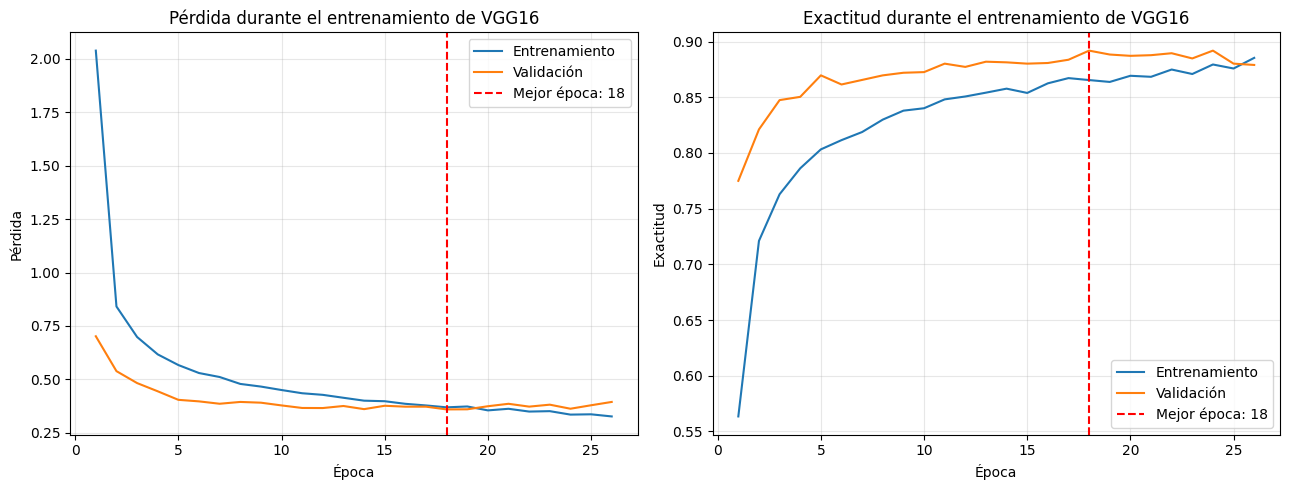

Mejor época según val_loss: 18
Menor val_loss: 0.36
Mayor val_accuracy: 0.8919


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

epocas_vgg = range(
    1,
    len(historial_vgg.history["loss"]) + 1
)

mejor_epoca_vgg = (
    np.argmin(historial_vgg.history["val_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pérdida
axes[0].plot(
    epocas_vgg,
    historial_vgg.history["loss"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas_vgg,
    historial_vgg.history["val_loss"],
    label="Validación"
)

axes[0].axvline(
    mejor_epoca_vgg,
    color="red",
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_vgg}"
)

axes[0].set_title("Pérdida durante el entrenamiento de VGG16")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Exactitud
axes[1].plot(
    epocas_vgg,
    historial_vgg.history["accuracy"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas_vgg,
    historial_vgg.history["val_accuracy"],
    label="Validación"
)

axes[1].axvline(
    mejor_epoca_vgg,
    color="red",
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_vgg}"
)

axes[1].set_title("Exactitud durante el entrenamiento de VGG16")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Exactitud")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Mejor época según val_loss:",
    mejor_epoca_vgg
)

print(
    "Menor val_loss:",
    round(min(historial_vgg.history["val_loss"]), 4)
)

print(
    "Mayor val_accuracy:",
    round(max(historial_vgg.history["val_accuracy"]), 4)
)

#### Interpretación de las curvas de aprendizaje

La menor pérdida de validación se alcanzó en la época 18. A partir de ese momento, la pérdida de entrenamiento continuó disminuyendo, mientras que la de validación presentó oscilaciones sin una mejora sostenida, lo que indica el inicio del sobreajuste.

Las curvas de exactitud de entrenamiento y validación permanecieron próximas durante gran parte del proceso. La exactitud de validación fue ligeramente superior en varias épocas, lo que puede relacionarse con el uso de **Dropout**, que solo actúa durante el entrenamiento.

### 9.6. Evaluación global de VGG16 sobre el conjunto de prueba

Se evaluará la mejor versión del modelo VGG16 sobre el conjunto de prueba depurado. Se informarán la **pérdida** y el **F1 macro**, establecido como métrica principal del trabajo.

In [ ]:
# Recuperar la mejor versión guardada de VGG16
modelo_vgg = tf.keras.models.load_model(
    str(carpeta_proyecto / "mejor_modelo_vgg.keras")
)

# Evaluar el modelo sobre el conjunto de prueba
test_loss_vgg, _ = modelo_vgg.evaluate(
    X_test_vgg,
    y_test_vgg,
    verbose=1
)

# Obtener las probabilidades predichas
probabilidades_vgg = modelo_vgg.predict(
    X_test_vgg,
    verbose=1
)

# Obtener la categoría predicha
y_pred_vgg = np.argmax(
    probabilidades_vgg,
    axis=1
)

# Calcular el F1 macro
f1_macro_vgg = f1_score(
    y_test_vgg,
    y_pred_vgg,
    average="macro"
)

print(f"\nPérdida en prueba: {test_loss_vgg:.4f}")
print(f"F1 macro de VGG16: {f1_macro_vgg:.4f}")

107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.8749 - loss: 0.3728
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step

Pérdida en prueba: 0.3728
F1 macro de VGG16: 0.8650


#### Interpretación de la evaluación global

VGG16 con la base congelada obtuvo una **pérdida** de 0,3728 y un **F1 macro** de 0,8650 sobre el conjunto de prueba. Este resultado sugiere que las características aprendidas en ImageNet, sin adaptación, permiten un desempeño moderado en la clasificación de las categorías celulares, lo que motiva la etapa de ajuste fino desarrollada más adelante. Las diferencias entre categorías se analizarán mediante la precisión y el recall por clase.

### 9.7. Evaluación del desempeño por clase

A continuación, se presentan la **precisión** y el **recall por categoría** obtenidos por VGG16.

In [ ]:
# Calcular precisión por categoría
precision_por_clase_vgg = precision_score(
    y_test_vgg,
    y_pred_vgg,
    labels=range(8),
    average=None,
    zero_division=0
)

# Calcular recall por categoría
recall_por_clase_vgg = recall_score(
    y_test_vgg,
    y_pred_vgg,
    labels=range(8),
    average=None,
    zero_division=0
)

# Contar las imágenes reales de cada categoría
cantidad_por_clase_vgg = np.bincount(
    y_test_vgg,
    minlength=8
)

# Organizar los resultados en una tabla
metricas_clase_vgg = pd.DataFrame({
    "Categoría": nombres_clases,
    "Precisión": precision_por_clase_vgg,
    "Recall": recall_por_clase_vgg,
    "Cantidad de imágenes": cantidad_por_clase_vgg
})

display(
    metricas_clase_vgg.round({
        "Precisión": 4,
        "Recall": 4
    })
)

,Categoría,Precisión,Recall,Cantidad de imágenes
0,Basófilo,0.8904,0.8320,244
1,Eosinófilo,0.8797,0.9375,624
2,Eritroblasto,0.8644,0.8199,311
3,Granulocitos inmaduros,0.7688,0.7927,579
4,Linfocito,0.8678,0.8642,243
5,Monocito,0.8160,0.7183,284
6,Neutrófilo,0.9129,0.9293,665
7,Plaqueta,0.9828,0.9745,470


#### Interpretación del desempeño por clase

VGG16 presentó su mejor desempeño en plaquetas, con una **precisión** de 0,9828 y un **recall** de 0,9745. También obtuvo valores elevados en neutrófilos y eosinófilos.

Las principales dificultades se observaron en granulocitos inmaduros, que presentaron la menor precisión (0,7688), y en monocitos, que mostraron el menor recall (0,7183). Esto indica que el modelo asignó incorrectamente otras células a la categoría de granulocitos inmaduros y no logró reconocer una proporción importante de los monocitos verdaderos.

### 9.8. Matriz de confusión de VGG16

A continuación, se presenta la matriz de confusión de VGG16 para identificar las categorías entre las que se produjeron los errores.

Imágenes correctamente clasificadas: 2992
Imágenes mal clasificadas: 428


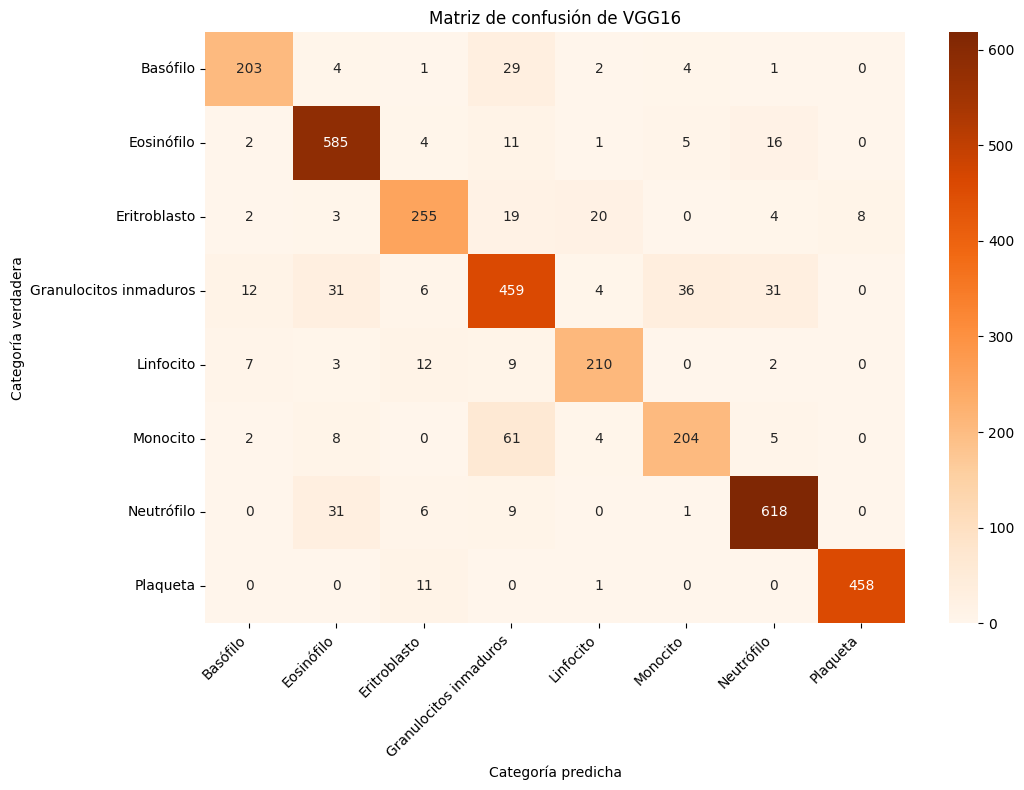

In [ ]:
# Calcular la matriz de confusión
matriz_vgg = confusion_matrix(
    y_test_vgg,
    y_pred_vgg,
    labels=range(8)
)

# Calcular clasificaciones correctas e incorrectas
aciertos_vgg = np.trace(matriz_vgg)
errores_vgg = matriz_vgg.sum() - aciertos_vgg

print(
    "Imágenes correctamente clasificadas:",
    aciertos_vgg
)
print(
    "Imágenes mal clasificadas:",
    errores_vgg
)

# Representar la matriz
plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_vgg,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

plt.title("Matriz de confusión de VGG16")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría verdadera")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Interpretación de la matriz de confusión

VGG16 clasificó correctamente 2.992 de las 3.420 imágenes y cometió 428 errores. La confusión más frecuente correspondió a 61 monocitos clasificados como granulocitos inmaduros. También se observaron errores entre granulocitos inmaduros, monocitos, eosinófilos y neutrófilos, posiblemente relacionados con características visuales compartidas en algunas imágenes, aunque no todos pertenecen a la misma línea de diferenciación.

También se identificaron 11 plaquetas clasificadas como eritroblastos y 8 eritroblastos clasificados como plaquetas. Aunque fueron menos frecuentes, estos errores resultan relevantes por las diferencias morfológicas y funcionales entre ambas categorías.

### 9.9. Análisis visual de imágenes mal clasificadas

A continuación, se muestran nueve imágenes clasificadas incorrectamente por VGG16, junto con su categoría verdadera, la categoría predicha y la probabilidad asignada a la predicción.

Total de imágenes mal clasificadas: 428


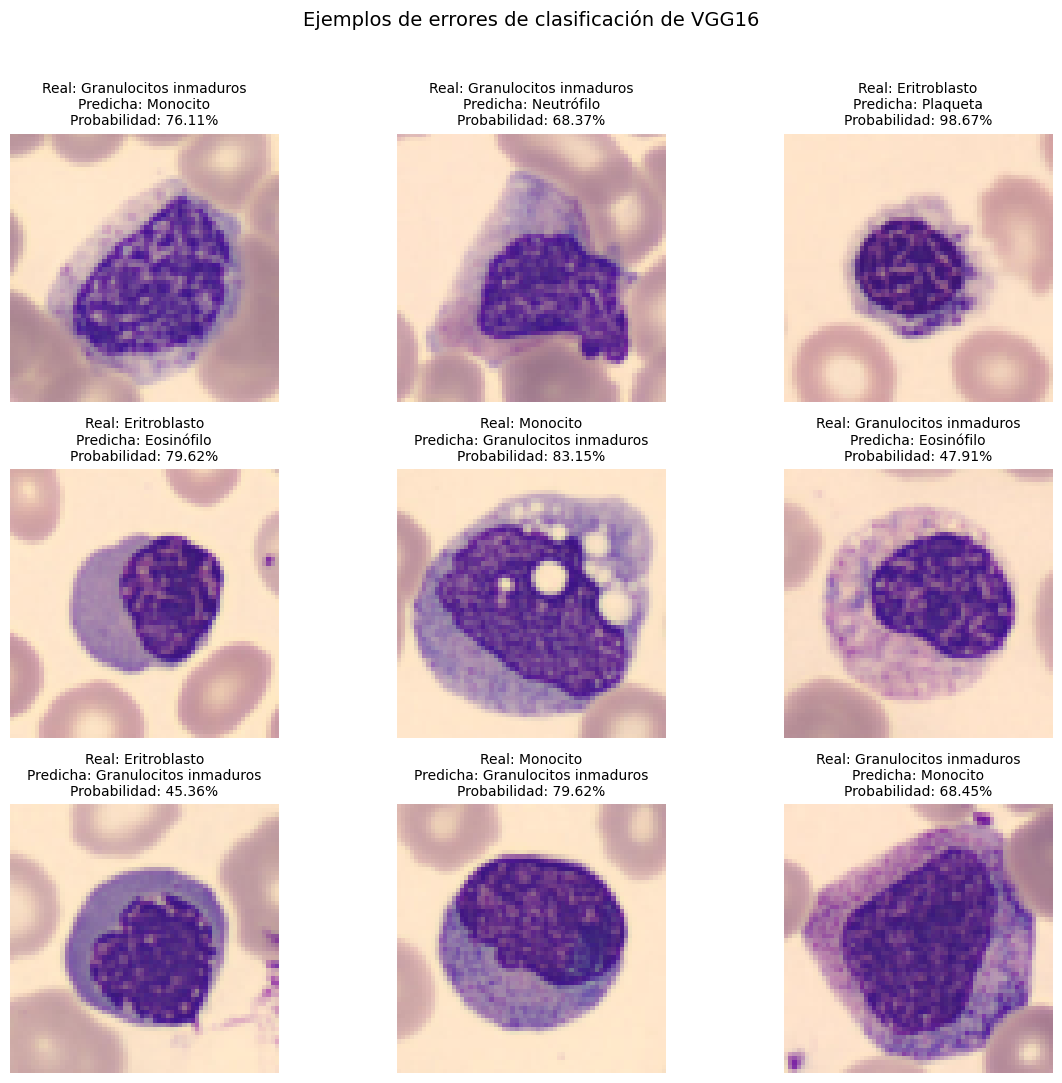

In [ ]:
# Identificar las imágenes mal clasificadas
indices_error_vgg = np.where(
    y_pred_vgg != y_test_vgg
)[0]

print(
    "Total de imágenes mal clasificadas:",
    len(indices_error_vgg)
)

# Seleccionar nueve errores de manera reproducible
rng_vgg = np.random.default_rng(42)

indices_muestra_error_vgg = rng_vgg.choice(
    indices_error_vgg,
    size=9,
    replace=False
)

# Mostrar las imágenes seleccionadas
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 11)
)

for ax, indice in zip(
    axes.ravel(),
    indices_muestra_error_vgg
):
    clase_real = int(y_test_vgg[indice])
    clase_predicha = int(y_pred_vgg[indice])

    probabilidad = probabilidades_vgg[
        indice,
        clase_predicha
    ]

    # Mostrar la imagen sin el preprocesamiento de VGG16
    ax.imshow(X_test_clean[indice])

    ax.set_title(
        f"Real: {nombres_clases[clase_real]}\n"
        f"Predicha: {nombres_clases[clase_predicha]}\n"
        f"Probabilidad: {probabilidad:.2%}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Ejemplos de errores de clasificación de VGG16",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### Interpretación de las imágenes mal clasificadas

Cuatro de las nueve imágenes corresponden a granulocitos inmaduros clasificados como monocitos, neutrófilos o eosinófilos, y dos a monocitos clasificados como granulocitos inmaduros, en coincidencia con las confusiones más frecuentes de la matriz.

Los tres eritroblastos fueron confundidos con plaqueta, eosinófilo o granulocito inmaduro. El caso más llamativo es el eritroblasto clasificado como plaqueta con una probabilidad de 98,67 %: se trata de una célula pequeña con un núcleo denso, por lo que el modelo pudo haber priorizado su tamaño reducido, a pesar de que las plaquetas no tienen núcleo.

Las probabilidades de los errores variaron entre 45,36 % y 98,67 %, por lo que algunas predicciones incorrectas se realizaron con una confianza muy elevada. Estos nueve casos constituyen una muestra ilustrativa de los 428 errores totales y no representan por sí solos su frecuencia general.


### 9.10. Síntesis del desempeño de VGG16 con la base congelada

VGG16 con la base congelada obtuvo una **pérdida** de 0,3728 y un **F1 macro** de 0,8650, con 2.992 clasificaciones correctas y 428 errores. El mejor desempeño se observó en plaquetas, mientras que las principales dificultades correspondieron a la precisión de los granulocitos inmaduros y al recall de los monocitos, con errores concentrados entre ambas categorías y, en menor medida, entre eritroblastos y plaquetas.

## 10. Preparación del ajuste fino de VGG16

Como segunda etapa de la transferencia de aprendizaje, se realizará el ajuste fino del último bloque convolucional de VGG16. El objetivo será permitir que parte de la base preentrenada adapte sus características generales a los patrones específicos de las imágenes de BloodMNIST.

Para evitar modificaciones bruscas de los pesos previamente aprendidos, se utilizará una tasa de aprendizaje menor que la empleada durante el entrenamiento inicial del clasificador.

### 10.1. Carga del mejor modelo VGG16 para iniciar el ajuste fino

In [ ]:
# Ruta del mejor modelo VGG16 con la base congelada
ruta_modelo_vgg = (
    carpeta_proyecto / "mejor_modelo_vgg.keras"
)

# Recuperar la mejor versión guardada
modelo_vgg = tf.keras.models.load_model(
    str(ruta_modelo_vgg)
)

# Recuperar la base VGG16 contenida en el modelo
base_vgg = modelo_vgg.get_layer("vgg16")

print("Modelo recuperado correctamente.")
print("Nombre de la base:", base_vgg.name)
print("Cantidad de capas de la base:", len(base_vgg.layers))

Modelo recuperado correctamente.
Nombre de la base: vgg16
Cantidad de capas de la base: 19


Se recuperó correctamente la mejor versión de VGG16 obtenida durante el entrenamiento inicial. La base preentrenada contiene 19 capas y será utilizada para configurar el ajuste fino.

## 11. Ajuste fino de VGG16

En esta etapa se habilitará el entrenamiento del último bloque convolucional de VGG16, mientras que los bloques anteriores permanecerán congelados.

### 11.1. Descongelamiento del último bloque convolucional

Se habilitarán las capas pertenecientes al bloque 5 de VGG16. Las capas de los primeros cuatro bloques permanecerán congeladas.

In [ ]:
# Habilitar la modificación de la base VGG16
base_vgg.trainable = True

# Descongelar solamente el último bloque convolucional
for capa in base_vgg.layers:
    if capa.name.startswith("block5"):
        capa.trainable = True
    else:
        capa.trainable = False

# Verificar el estado de cada capa
for capa in base_vgg.layers:
    print(
        f"{capa.name:<20} "
        f"Entrenable: {capa.trainable}"
    )

input_layer_1        Entrenable: False
block1_conv1         Entrenable: False
block1_conv2         Entrenable: False
block1_pool          Entrenable: False
block2_conv1         Entrenable: False
block2_conv2         Entrenable: False
block2_pool          Entrenable: False
block3_conv1         Entrenable: False
block3_conv2         Entrenable: False
block3_conv3         Entrenable: False
block3_pool          Entrenable: False
block4_conv1         Entrenable: False
block4_conv2         Entrenable: False
block4_conv3         Entrenable: False
block4_pool          Entrenable: False
block5_conv1         Entrenable: True
block5_conv2         Entrenable: True
block5_conv3         Entrenable: True
block5_pool          Entrenable: True


#### Interpretación

Los primeros cuatro bloques de VGG16 permanecieron congelados y se habilitó el entrenamiento del quinto bloque. De esta manera, se conservarán las características visuales generales aprendidas previamente, mientras que las capas más profundas podrán adaptarse a los patrones específicos de **BloodMNIST**.

### 11.2. Compilación para el ajuste fino

Después de modificar el estado entrenable de las capas, es necesario recompilar el modelo. Se utilizará una tasa de aprendizaje reducida para actualizar gradualmente los pesos preentrenados del último bloque convolucional.

In [ ]:
# Recompilar el modelo después de descongelar el bloque 5
modelo_vgg.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    # La exactitud se utilizará solo para seguir el entrenamiento
    metrics=["accuracy"]
)

modelo_vgg.summary()

Model: "VGG16_BloodMNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,384 (56.39 MB)

 Trainable params: 7,146,120 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

#### Interpretación de la configuración

La cantidad total de parámetros se mantuvo en 14.781.384, pero los parámetros entrenables aumentaron de 66.696 a 7.146.120 al descongelar el último bloque convolucional, mientras que los 7.635.264 parámetros de los bloques anteriores permanecieron congelados.

### 11.3. Entrenamiento del ajuste fino

Debido a que el ajuste fino parte de un modelo previamente entrenado y aumenta considerablemente la cantidad de parámetros entrenables, se establecerá un máximo de 15 épocas. Además, se utilizará una paciencia de cinco épocas para detener el entrenamiento si la pérdida de validación no mejora, limitando así el riesgo de sobreajuste.

El entrenamiento se realizará con lotes de 32 imágenes y se conservará la versión que alcance la menor pérdida de validación.

#### 11.3.1. Configuración de callbacks para el ajuste fino

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Ruta para guardar el mejor modelo ajustado
ruta_modelo_vgg_ft = (
    carpeta_proyecto /
    "mejor_modelo_vgg_finetuning.keras"
)

# Detener el entrenamiento si val_loss no mejora
early_stopping_vgg_ft = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Guardar solamente el modelo con menor val_loss
model_checkpoint_vgg_ft = ModelCheckpoint(
    filepath=str(ruta_modelo_vgg_ft),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Callbacks configurados correctamente.")
print("El mejor modelo se guardará en:", ruta_modelo_vgg_ft)

Callbacks configurados correctamente.
El mejor modelo se guardará en: /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg_finetuning.keras


Los callbacks quedaron configurados correctamente. Durante el ajuste fino, se conservará en Google Drive la versión del modelo que obtenga la menor pérdida de validación.

#### 11.3.2. Ejecución del ajuste fino

In [ ]:
# Ejecutar el ajuste fino del último bloque de VGG16
historial_vgg_ft = modelo_vgg.fit(
    X_train_vgg,
    y_train_vgg,
    validation_data=(
        X_val_vgg,
        y_val_vgg
    ),
    epochs=15,
    batch_size=32,
    callbacks=[
        early_stopping_vgg_ft,
        model_checkpoint_vgg_ft
    ],
    verbose=1
)

Epoch 1/15
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8774 - loss: 0.3509
Epoch 1: val_loss improved from None to 0.31158, saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg_finetuning.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg_finetuning.keras
374/374 ━━━━━━━━━━━━━━━━━━━━ 23s 50ms/step - accuracy: 0.8839 - loss: 0.3387 - val_accuracy: 0.9053 - val_loss: 0.3116
Epoch 2/15
373/374 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9158 - loss: 0.2476
Epoch 2: val_loss improved from 0.31158 to 0.27376, saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg_finetuning.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TP8_BloodMNIST/mejor_modelo_vgg_finetuning.keras
374/374 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.9161 - loss: 0.2481 - val_accuracy: 0.9199 - val_loss: 0.2738
Epoch 3/15
373/374 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9289 - loss: 0.1954
Epoch 3: v

#### Interpretación del ajuste fino

La menor pérdida de validación fue 0,2503 y se alcanzó en la **época 5**. Después de esa época, la pérdida de entrenamiento continuó disminuyendo, mientras que la pérdida de validación presentó oscilaciones y no volvió a mejorar, lo que indica un sobreajuste progresivo.

El entrenamiento finalizó en la **época 10** después de cinco épocas consecutivas sin mejoras y restauró automáticamente los pesos correspondientes a la época 5.

### 11.4. Curvas de aprendizaje del ajuste fino

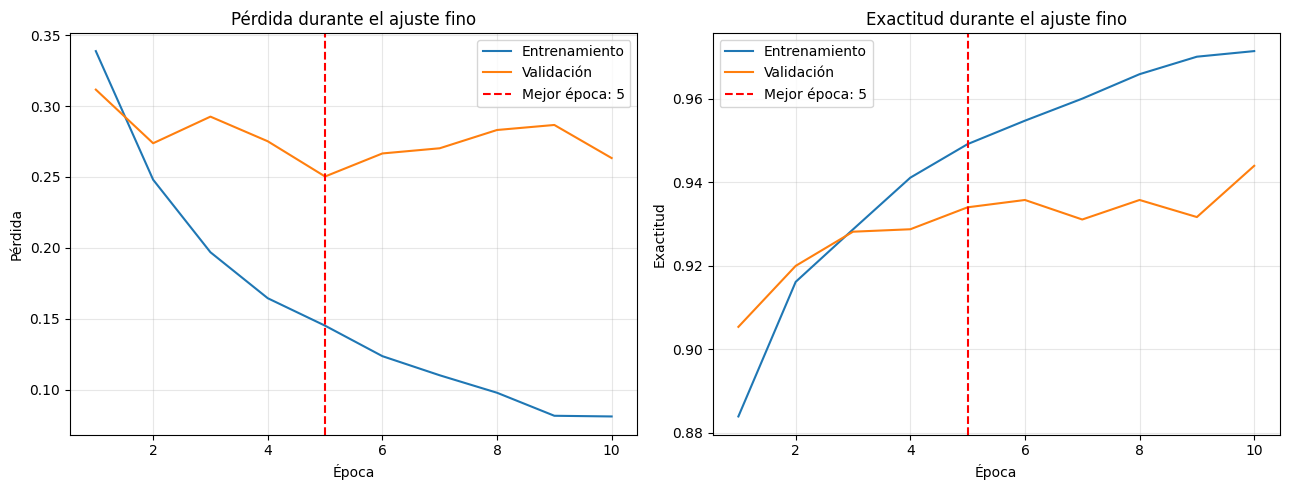

Mejor época según val_loss: 5
Menor val_loss: 0.2503
Mayor val_accuracy: 0.9439


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

epocas_vgg_ft = range(
    1,
    len(historial_vgg_ft.history["loss"]) + 1
)

mejor_epoca_vgg_ft = (
    np.argmin(
        historial_vgg_ft.history["val_loss"]
    ) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pérdida
axes[0].plot(
    epocas_vgg_ft,
    historial_vgg_ft.history["loss"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas_vgg_ft,
    historial_vgg_ft.history["val_loss"],
    label="Validación"
)

axes[0].axvline(
    mejor_epoca_vgg_ft,
    color="red",
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_vgg_ft}"
)

axes[0].set_title(
    "Pérdida durante el ajuste fino"
)
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Exactitud
axes[1].plot(
    epocas_vgg_ft,
    historial_vgg_ft.history["accuracy"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas_vgg_ft,
    historial_vgg_ft.history["val_accuracy"],
    label="Validación"
)

axes[1].axvline(
    mejor_epoca_vgg_ft,
    color="red",
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_vgg_ft}"
)

axes[1].set_title(
    "Exactitud durante el ajuste fino"
)
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Exactitud")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Mejor época según val_loss:",
    mejor_epoca_vgg_ft
)

print(
    "Menor val_loss:",
    round(
        min(historial_vgg_ft.history["val_loss"]),
        4
    )
)

print(
    "Mayor val_accuracy:",
    round(
        max(historial_vgg_ft.history["val_accuracy"]),
        4
    )
)

#### Interpretación de las curvas

Las curvas muestran que la pérdida de entrenamiento disminuyó de forma sostenida, mientras que la de validación dejó de mejorar después de la época 5. La creciente separación entre ambas evidencia un sobreajuste progresivo.

La exactitud de validación alcanzó su máximo (94,39 %) en la época 10. Sin embargo, se conservaron los pesos de la época 5 porque el criterio de selección fue la menor pérdida de validación, que además de los aciertos considera la confianza con que el modelo asigna las probabilidades.

### 11.5. Evaluación global del modelo ajustado

Para evaluar el resultado del ajuste fino, recuperaré la versión guardada en la época que obtuvo la menor pérdida de validación. Sobre el conjunto de prueba calcularé la **pérdida** y el **F1 macro** definido como métrica principal.


In [ ]:
# Cargar la mejor versión obtenida durante el ajuste fino
modelo_vgg_ft = tf.keras.models.load_model(
    str(ruta_modelo_vgg_ft)
)

# Evaluar sobre el conjunto de prueba
test_loss_vgg_ft, test_accuracy_vgg_ft = (
    modelo_vgg_ft.evaluate(
        X_test_vgg,
        y_test_vgg,
        verbose=1
    )
)

# Obtener las probabilidades estimadas para cada clase
probabilidades_vgg_ft = modelo_vgg_ft.predict(
    X_test_vgg,
    verbose=1
)

# Seleccionar la clase con mayor probabilidad
y_pred_vgg_ft = np.argmax(
    probabilidades_vgg_ft,
    axis=1
)

# Calcular el F1 macro
f1_macro_vgg_ft = f1_score(
    y_test_vgg,
    y_pred_vgg_ft,
    average="macro"
)

print(f"\nPérdida en prueba: {test_loss_vgg_ft:.4f}")
print(
    "F1 macro de VGG16 con ajuste fino: "
    f"{f1_macro_vgg_ft:.4f}"
)

107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9278 - loss: 0.2491
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step

Pérdida en prueba: 0.2491
F1 macro de VGG16 con ajuste fino: 0.9220


#### Interpretación de la evaluación global

El modelo VGG16 con ajuste fino obtuvo una **pérdida** de 0,2491 y un **F1 macro** de 0,9220 sobre el conjunto de prueba, lo que indica un desempeño global elevado. Las diferencias entre categorías se analizarán mediante la precisión y el recall por clase.

### 11.6. Evaluación del desempeño por clase

In [ ]:
from sklearn.metrics import classification_report

# Convertir las etiquetas reales en un vector unidimensional
y_test_vgg_1d = np.asarray(y_test_vgg).ravel()

# Calcular las métricas para cada categoría
reporte_vgg_ft = classification_report(
    y_test_vgg_1d,
    y_pred_vgg_ft,
    labels=range(8),
    target_names=nombres_clases,
    output_dict=True,
    zero_division=0
)

# Organizar los resultados en una tabla
tabla_vgg_ft = pd.DataFrame({
    "Categoría": nombres_clases,
    "Precisión": [
        reporte_vgg_ft[clase]["precision"]
        for clase in nombres_clases
    ],
    "Recall": [
        reporte_vgg_ft[clase]["recall"]
        for clase in nombres_clases
    ],
    "Cantidad de imágenes": [
        int(reporte_vgg_ft[clase]["support"])
        for clase in nombres_clases
    ]
})

# Mostrar la tabla
tabla_vgg_ft.style.format({
    "Precisión": "{:.4f}",
    "Recall": "{:.4f}"
})

,Categoría,Precisión,Recall,Cantidad de imágenes
0,Basófilo,0.9367,0.9098,244
1,Eosinófilo,0.9759,0.9728,624
2,Eritroblasto,0.9604,0.8585,311
3,Granulocitos inmaduros,0.8163,0.8981,579
4,Linfocito,0.9177,0.9177,243
5,Monocito,0.8700,0.8486,284
6,Neutrófilo,0.9630,0.9398,665
7,Plaqueta,0.9811,0.9957,470


#### Interpretación del desempeño por clase

Las plaquetas obtuvieron los valores más altos, con una **precisión** de 0,9811 y un **recall** de 0,9957, seguidas por los eosinófilos (0,9759 y 0,9728).

La menor **precisión** correspondió a los granulocitos inmaduros (0,8163), lo que indica una mayor presencia de falsos positivos, es decir, imágenes de otras categorías clasificadas incorrectamente como granulocitos inmaduros. El menor **recall** se observó en los monocitos (0,8486), seguidos por los eritroblastos (0,8585), que fueron las categorías con mayor proporción de imágenes reales no reconocidas.

### 11.7. Matriz de confusión del modelo VGG16 con ajuste fino

Total de imágenes correctamente clasificadas: 3173
Total de imágenes mal clasificadas: 247


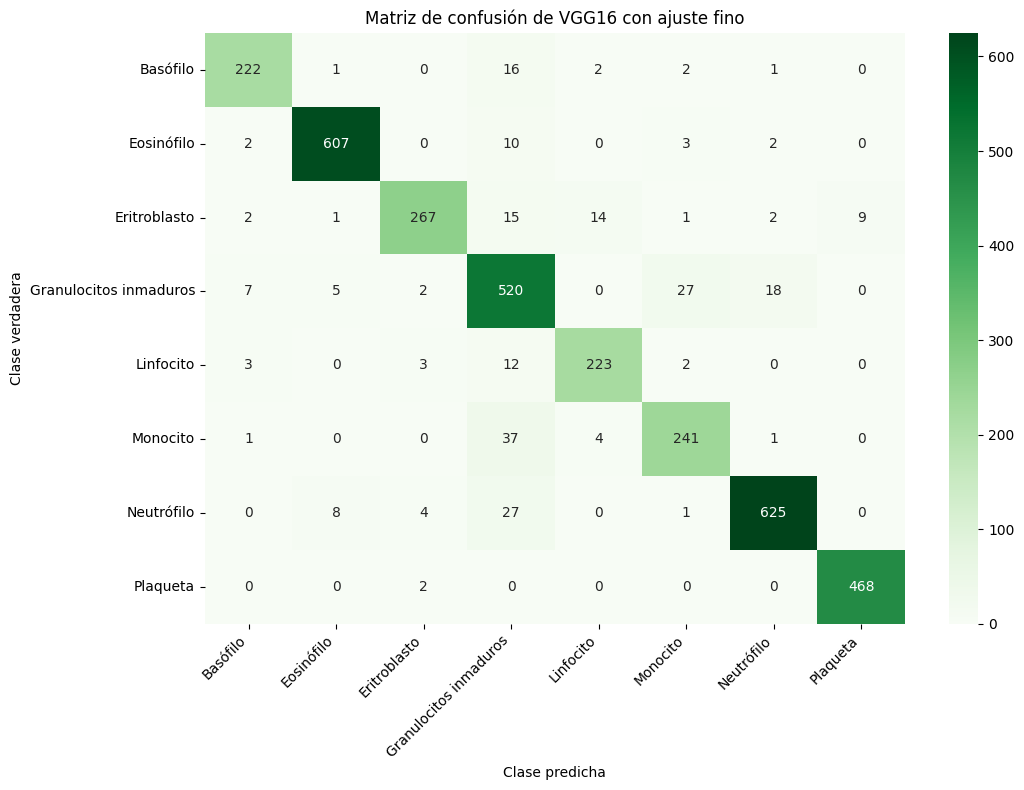

In [ ]:
# Construir la matriz con las predicciones del modelo ajustado
matriz_vgg_ft = confusion_matrix(
    y_test_vgg_1d,
    y_pred_vgg_ft,
    labels=range(8)
)

# Calcular la cantidad de clasificaciones correctas e incorrectas
errores_vgg_ft = np.sum(
    y_test_vgg_1d != y_pred_vgg_ft
)

aciertos_vgg_ft = (
    len(y_test_vgg_1d) - errores_vgg_ft
)

print(
    "Total de imágenes correctamente clasificadas:",
    aciertos_vgg_ft
)

print(
    "Total de imágenes mal clasificadas:",
    errores_vgg_ft
)

# Representar la matriz de confusión
plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_vgg_ft,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

plt.title(
    "Matriz de confusión de VGG16 con ajuste fino"
)
plt.xlabel("Clase predicha")
plt.ylabel("Clase verdadera")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Interpretación de la matriz de confusión

El modelo clasificó correctamente 3.173 de las 3.420 imágenes del conjunto de prueba y cometió 247 errores.

Los granulocitos inmaduros fueron la principal categoría receptora de errores: 37 monocitos, 27 neutrófilos, 16 basófilos, 15 eritroblastos, 12 linfocitos y 10 eosinófilos fueron asignados a esta categoría, lo que explica su menor precisión. A su vez, 27 granulocitos inmaduros fueron clasificados como monocitos y 18 como neutrófilos.

También se observaron errores en los eritroblastos: 14 fueron clasificados como linfocitos y 9 como plaquetas. La confusión con los linfocitos podría relacionarse con que ambas células presentan, a esta resolución, un núcleo redondo y denso con escaso citoplasma. La confusión con las plaquetas, aunque menos frecuente, resulta relevante por las diferencias de tamaño y por la ausencia de núcleo en estas últimas.

### 11.8. Análisis visual de errores del modelo VGG16 con ajuste fino



Total de imágenes mal clasificadas: 247


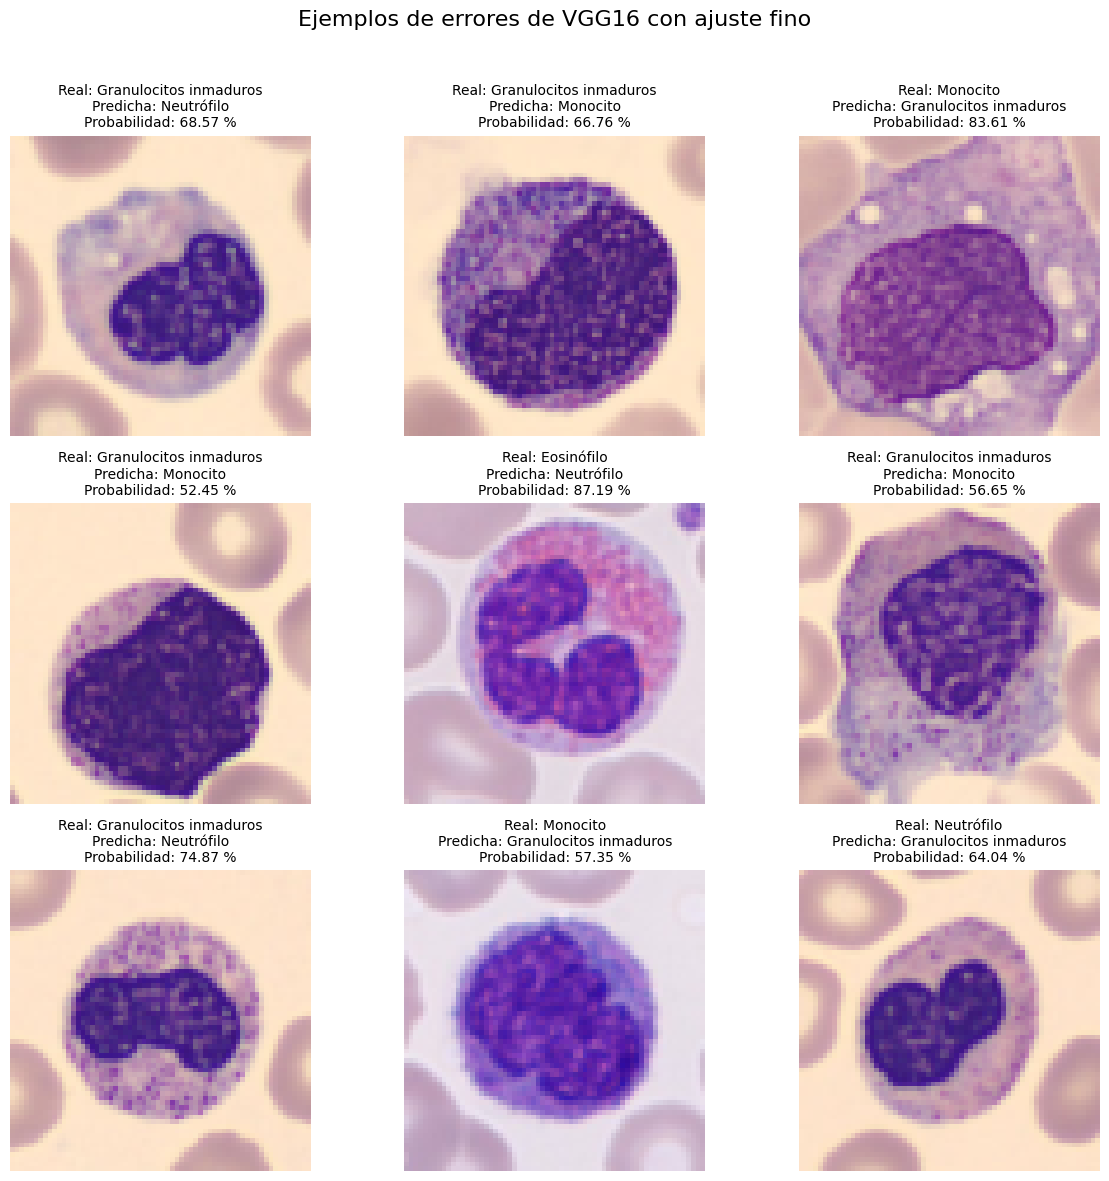

In [ ]:
# Identificar las imágenes clasificadas incorrectamente
indices_error_vgg_ft = np.where(
    y_pred_vgg_ft != y_test_vgg_1d
)[0]

print(
    "Total de imágenes mal clasificadas:",
    len(indices_error_vgg_ft)
)

# Seleccionar nueve errores de manera reproducible
rng_vgg_ft = np.random.default_rng(42)

indices_muestra_error_vgg_ft = rng_vgg_ft.choice(
    indices_error_vgg_ft,
    size=9,
    replace=False
)

# Crear la figura
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

fig.suptitle(
    "Ejemplos de errores de VGG16 con ajuste fino",
    fontsize=16
)

# Mostrar las imágenes seleccionadas
for ax, i in zip(
    axes.ravel(),
    indices_muestra_error_vgg_ft
):
    # Categoría verdadera y categoría predicha
    clase_real = int(y_test_vgg_1d[i])
    clase_predicha = int(y_pred_vgg_ft[i])

    # Probabilidad asignada a la predicción
    probabilidad = (
        probabilidades_vgg_ft[
            i,
            clase_predicha
        ] * 100
    )

    # Crear una copia para no modificar X_test_vgg
    imagen = X_test_vgg[i].copy()

    # Revertir la resta de las medias aplicada por VGG16
    imagen[..., 0] += 103.939
    imagen[..., 1] += 116.779
    imagen[..., 2] += 123.680

    # Convertir nuevamente de BGR a RGB
    imagen = imagen[..., ::-1]

    # Recuperar el rango válido de los píxeles
    imagen = np.clip(
        imagen,
        0,
        255
    ).astype("uint8")

    # Mostrar la imagen
    ax.imshow(imagen)

    titulo = "\n".join([
        f"Real: {nombres_clases[clase_real]}",
        f"Predicha: {nombres_clases[clase_predicha]}",
        f"Probabilidad: {probabilidad:.2f} %"
    ])

    ax.set_title(
        titulo,
        fontsize=10
    )

    ax.axis("off")

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()

#### Interpretación de las imágenes mal clasificadas

En la muestra predominaron las confusiones entre granulocitos inmaduros, monocitos y neutrófilos. Tres granulocitos inmaduros fueron clasificados como monocitos y dos como neutrófilos; a su vez, dos monocitos y un neutrófilo fueron clasificados como granulocitos inmaduros.

La confusión con neutrófilos podría relacionarse con la continuidad de la maduración granulocítica: algunos granulocitos inmaduros presentan núcleos arriñonados o en banda, similares a los de un neutrófilo poco segmentado.

El error más llamativo es un eosinófilo clasificado como neutrófilo con una probabilidad de 87,19 %, a pesar de que la imagen muestra la granulación rosada característica de los eosinófilos. Esto sugiere que, en ese caso, el modelo pudo dar más peso a la forma lobulada del núcleo que al color de los gránulos.

La mayoría de los errores seleccionados presentó probabilidades moderadas, comprendidas entre 52,45 % y 87,19 %, lo que refleja incertidumbre del modelo frente a algunos casos morfológicamente intermedios. Estos nueve casos constituyen una muestra ilustrativa de los 247 errores totales y no representan por sí solos su frecuencia general.




### 11.9. Síntesis del desempeño de VGG16 con ajuste fino

VGG16 con ajuste fino obtuvo una **pérdida** de 0,2491 y un **F1 macro** de 0,9220 sobre el conjunto de prueba, con 3.173 clasificaciones correctas y 247 errores.

El desempeño fue especialmente elevado en plaquetas y eosinófilos. Las principales dificultades se observaron en el reconocimiento de monocitos y eritroblastos y en la asignación incorrecta de otras categorías como granulocitos inmaduros.

## 12. Comparación final de los modelos

Para realizar la comparación final, recuperaré la mejor versión guardada de cada modelo y calcularé el **F1 macro** sobre el mismo conjunto de prueba.

In [ ]:
# Rutas de las mejores versiones guardadas
ruta_cnn_final = (
    carpeta_proyecto /
    "mejor_modelo_cnn.keras"
)

ruta_vgg_final = (
    carpeta_proyecto /
    "mejor_modelo_vgg.keras"
)

ruta_vgg_ft_final = (
    carpeta_proyecto /
    "mejor_modelo_vgg_finetuning.keras"
)

# Recuperar las mejores versiones de los modelos
modelo_cnn_final = tf.keras.models.load_model(
    str(ruta_cnn_final)
)

modelo_vgg_final = tf.keras.models.load_model(
    str(ruta_vgg_final)
)

modelo_vgg_ft_final = tf.keras.models.load_model(
    str(ruta_vgg_ft_final)
)

# Predicciones de la CNN propia
probabilidades_cnn_final = modelo_cnn_final.predict(
    X_test_cnn,
    verbose=1
)

y_pred_cnn_final = np.argmax(
    probabilidades_cnn_final,
    axis=1
)

# Predicciones de VGG16 con la base congelada
probabilidades_vgg_final = modelo_vgg_final.predict(
    X_test_vgg,
    verbose=1
)

y_pred_vgg_final = np.argmax(
    probabilidades_vgg_final,
    axis=1
)

# Predicciones de VGG16 con ajuste fino
probabilidades_vgg_ft_final = modelo_vgg_ft_final.predict(
    X_test_vgg,
    verbose=1
)

y_pred_vgg_ft_final = np.argmax(
    probabilidades_vgg_ft_final,
    axis=1
)

# Calcular el F1 macro de cada modelo
f1_cnn_final = f1_score(
    y_test_cnn,
    y_pred_cnn_final,
    average="macro"
)

f1_vgg_final = f1_score(
    y_test_vgg,
    y_pred_vgg_final,
    average="macro"
)

f1_vgg_ft_final = f1_score(
    y_test_vgg,
    y_pred_vgg_ft_final,
    average="macro"
)

# Construir la tabla comparativa
comparacion_final = pd.DataFrame({
    "Modelo": [
        "CNN propia",
        "VGG16 congelada",
        "VGG16 con ajuste fino"
    ],
    "F1 macro": [
        f1_cnn_final,
        f1_vgg_final,
        f1_vgg_ft_final
    ]
})

# Ordenar los modelos desde el mayor al menor F1 macro
comparacion_final = comparacion_final.sort_values(
    by="F1 macro",
    ascending=False
).reset_index(drop=True)

# Mostrar la comparación final
display(
    comparacion_final.style.format({
        "F1 macro": "{:.4f}"
    })
)

107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step


,Modelo,F1 macro
0,CNN propia,0.9562
1,VGG16 con ajuste fino,0.9220
2,VGG16 congelada,0.8650


#### Interpretación

La CNN propia obtuvo el mayor **F1 macro** (0,9562), seguida por VGG16 con ajuste fino (0,9220) y VGG16 con la base congelada (0,8650). El ajuste fino mejoró el desempeño de VGG16 en 0,057, pero no alcanzó el nivel de la CNN propia, que la superó por 0,034.

Para completar la comparación, a continuación se analizan el costo computacional de cada modelo y su desempeño en cada categoría.

### 12.1. Costo computacional de los modelos

Además del desempeño, se comparará la cantidad de parámetros y el tiempo de entrenamiento de cada modelo. Los tiempos corresponden a la suma de los segundos por época informados por Keras durante el entrenamiento en una GPU T4. En el caso del ajuste fino, se suma el tiempo de la etapa con la base congelada, ya que parte de ese modelo.

In [ ]:
# Costo computacional de cada modelo
# Tiempos: suma de los segundos por época informados por Keras (GPU T4)
costo_modelos = pd.DataFrame({
    "Modelo": ["CNN propia", "VGG16 congelada", "VGG16 con ajuste fino"],
    "Parámetros totales": [
        modelo_cnn_final.count_params(),
        modelo_vgg_final.count_params(),
        modelo_vgg_ft_final.count_params()
    ],
    "Parámetros entrenables": [1_142_984, 66_696, 7_146_120],
    "Épocas ejecutadas": [23, 26, 26 + 10],
    "Tiempo de entrenamiento (s)": [78, 245, 245 + 151],
    "F1 macro": [f1_cnn_final, f1_vgg_final, f1_vgg_ft_final]
})

display(costo_modelos.style.format({
    "Parámetros totales": "{:,.0f}",
    "Parámetros entrenables": "{:,.0f}",
    "F1 macro": "{:.4f}"
}))

,Modelo,Parámetros totales,Parámetros entrenables,Épocas ejecutadas,Tiempo de entrenamiento (s),F1 macro
0,CNN propia,"1,142,984","1,142,984",23,78,0.9562
1,VGG16 congelada,"14,781,384","66,696",26,245,0.8650
2,VGG16 con ajuste fino,"14,781,384","7,146,120",36,396,0.9220


#### Interpretación del costo computacional

La CNN propia fue el modelo más eficiente: con 1.142.984 parámetros, aproximadamente 13 veces menos que VGG16 (14.781.384), completó su entrenamiento en 78 segundos. VGG16 con ajuste fino requirió 396 segundos sumando sus dos etapas, es decir, unas cinco veces más tiempo.

Aunque VGG16 con la base congelada solo actualizó 66.696 parámetros, su entrenamiento tardó 245 segundos, tres veces más que la CNN propia. Esto se debe a que, aun sin modificar sus pesos, cada imagen debe atravesar toda la base convolucional de VGG16 en cada época. Por lo tanto, la cantidad de parámetros entrenables no determina por sí sola el costo del entrenamiento: también influye el tamaño total de la red.

El ajuste fino aumentó los parámetros entrenables a 7.146.120 y elevó el F1 macro de 0,8650 a 0,9220, pero no alcanzó el desempeño de la CNN propia (0,9562). En consecuencia, la CNN propia obtuvo el mejor resultado con el menor costo computacional, por lo que el mayor tamaño y la complejidad de VGG16 no se tradujeron en una ventaja para este problema.

### 12.2. Desempeño por categoría de los tres modelos

Para comparar el comportamiento de los modelos en cada categoría celular, se calculará el F1 por clase y se representará en un gráfico de barras agrupadas.

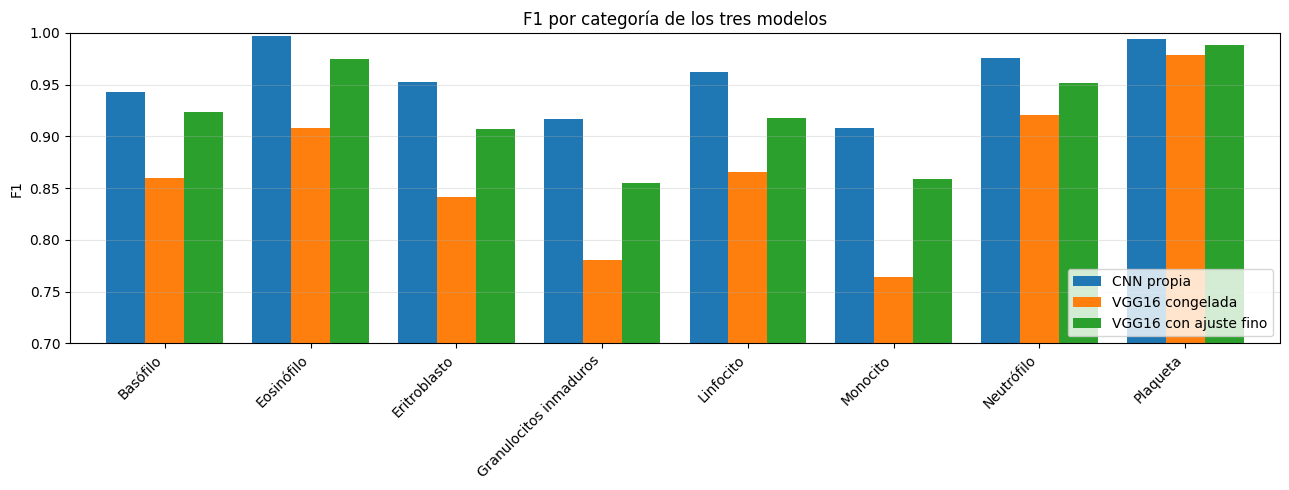

,CNN propia,VGG16 congelada,VGG16 con ajuste fino
Basófilo,0.9429,0.8602,0.9231
Eosinófilo,0.9968,0.9077,0.9743
Eritroblasto,0.9527,0.8416,0.9066
Granulocitos inmaduros,0.9172,0.7806,0.8553
Linfocito,0.9618,0.8660,0.9177
Monocito,0.9084,0.7640,0.8592
Neutrófilo,0.9760,0.9210,0.9513
Plaqueta,0.9936,0.9786,0.9884


In [ ]:
# F1 por categoría para los tres modelos
f1_por_clase = pd.DataFrame({
    "CNN propia": f1_score(
        y_test_cnn, y_pred_cnn_final,
        labels=range(8), average=None
    ),
    "VGG16 congelada": f1_score(
        y_test_vgg, y_pred_vgg_final,
        labels=range(8), average=None
    ),
    "VGG16 con ajuste fino": f1_score(
        y_test_vgg, y_pred_vgg_ft_final,
        labels=range(8), average=None
    )
}, index=nombres_clases)

ax = f1_por_clase.plot(kind="bar", figsize=(13, 5), width=0.8)
ax.set_title("F1 por categoría de los tres modelos")
ax.set_ylabel("F1")
ax.set_ylim(0.7, 1.0)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(f1_por_clase.style.format("{:.4f}"))

#### Interpretación del desempeño por categoría

La CNN propia obtuvo el mayor F1 en las ocho categorías, seguida siempre por VGG16 con ajuste fino y, por último, por VGG16 con la base congelada. Su ventaja no depende de unas pocas clases, sino que se mantiene en todo el conjunto de prueba.

Los tres modelos coincidieron en sus categorías más difíciles, monocitos y granulocitos inmaduros, y en la mejor reconocida, las plaquetas (F1 entre 0,9786 y 0,9936). Las diferencias entre modelos fueron mayores justamente en las categorías difíciles: entre la CNN propia y VGG16 congelada, la brecha fue de 0,1444 en monocitos y 0,1366 en granulocitos inmaduros, frente a solo 0,0150 en plaquetas. El ajuste fino redujo esas brechas, con sus mayores mejoras en monocitos (+0,0952) y granulocitos inmaduros (+0,0747).

La CNN propia también fue la más homogénea: su F1 varió entre 0,9084 y 0,9968, mientras que el de VGG16 congelada lo hizo entre 0,7640 y 0,9786.

### 12.3. Interpretación de la comparación final

La **CNN propia** superó a VGG16 tanto en **F1 macro** como en costo computacional y en cada una de las ocho categorías. Este resultado puede explicarse por tres factores.

Primero, VGG16 fue originalmente entrenada sobre imágenes de 224 × 224 píxeles: con entradas de 64 × 64, sus cinco capas de agrupamiento reducen las imágenes a mapas de 2 × 2, lo que elimina gran parte de la información espacial. La CNN propia, en cambio, conserva mapas de 8 × 8.

Segundo, las características aprendidas en ImageNet, formado por objetos y escenas cotidianas, difieren de las imágenes microscópicas de células teñidas, por lo que solo resultan parcialmente transferibles. Esto explica que el ajuste fino haya mejorado sobre todo a las categorías morfológicamente similares.

Tercero, una arquitectura más pequeña y entrenada directamente sobre el dominio resultó suficiente para la complejidad del problema.

Que los tres modelos coincidan en sus categorías más difíciles sugiere que esas dificultades dependen de las imágenes más que de una arquitectura en particular. Aunque monocitos y granulocitos inmaduros pertenecen a series celulares distintas, comparten un progenitor común y presentan rasgos visuales semejantes, como un tamaño celular grande, un citoplasma amplio y núcleos arriñonados o indentados, especialmente en el caso de los metamielocitos. Los detalles que permiten diferenciarlos, como la textura de la cromatina, el color del citoplasma y el tipo de granulación, son difíciles de apreciar en imágenes de 64 × 64 píxeles.

Al reejecutar el notebook completo, los resultados de la CNN propia y de VGG16 con ajuste fino variaron levemente (el F1 macro pasó de 0,9558 a 0,9562 y de 0,9293 a 0,9220, respectivamente), a pesar de haberse fijado una semilla, debido a operaciones no deterministas de la GPU. La diferencia entre la CNN propia y el segundo mejor modelo (0,034) supera ampliamente esa variación, por lo que la elección se mantiene.

De acuerdo con el **F1 macro**, establecido como **métrica principal**, y considerando además su menor costo computacional, la **CNN propia** fue seleccionada como modelo final.

## 13. Conclusiones

Se selecciona la **CNN propia** como modelo final para clasificar las imágenes de BloodMNIST, ya que obtuvo el mejor desempeño (F1 macro de 0,9562) con el menor costo computacional. La transferencia de aprendizaje con VGG16 no superó a una red diseñada específicamente para el problema, aun después del ajuste fino, lo que muestra que un modelo más grande y preentrenado no es necesariamente la mejor opción cuando las imágenes son pequeñas y pertenecen a un dominio muy distinto al de ImageNet.

La depuración previa del dataset fue una etapa relevante del trabajo: la detección de imágenes duplicadas entre conjuntos y de una imagen con etiquetas contradictorias permitió evitar fugas de información y realizar una evaluación más confiable.

Las métricas auxiliares permitieron identificar la naturaleza de los errores que el F1 macro resume en un único valor. En los tres modelos, los granulocitos inmaduros presentaron la menor **precisión**, porque recibieron imágenes de muchas otras categorías, mientras que los monocitos tuvieron el menor **recall**, porque una parte de ellos no fue reconocida. La **matriz de confusión** mostró que ambos problemas estaban conectados: la confusión más frecuente fue la de monocitos clasificados como granulocitos inmaduros, dos categorías con características morfológicas semejantes. La inspección visual evidenció además que algunas predicciones incorrectas se realizaron con probabilidades muy elevadas, por lo que la confianza asignada por el modelo no garantiza que la predicción sea correcta. En dos eritroblastos mal clasificados por la CNN propia, el recorte incluía otra célula o material de tinción intensa, lo que sugiere que elementos ajenos a la célula principal podrían influir en algunas predicciones.

Como posibles mejoras, se propone incorporar técnicas de aumento de datos (*data augmentation*), que no se aplicaron en ninguno de los modelos; evaluar las versiones de mayor resolución de BloodMNIST (128 × 128 y 224 × 224), que podrían favorecer especialmente a VGG16; y repetir los entrenamientos con distintas semillas para confirmar la estabilidad de los resultados.

Los resultados fueron satisfactorios para los objetivos experimentales del trabajo. No obstante, los modelos no pueden considerarse validados para su aplicación clínica: para avanzar en esa dirección serían necesarias imágenes de mayor resolución, datos externos y la evaluación de profesionales especializados.

## 14. Bibliografía

- Acevedo, A., Merino, A., Alférez, S., Molina, Á., Boldú, L. y Rodellar, J. (2020). A dataset of microscopic peripheral blood cell images for development of automatic recognition systems. *Data in Brief, 30*, 105474. https://doi.org/10.1016/j.dib.2020.105474

- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K. y Fei-Fei, L. (2009). *ImageNet: A large-scale hierarchical image database*. IEEE Conference on Computer Vision and Pattern Recognition, 248–255. https://doi.org/10.1109/CVPR.2009.5206848

- James, G., Witten, D., Hastie, T. y Tibshirani, R. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer.

- Simonyan, K. y Zisserman, A. (2015). *Very deep convolutional networks for large-scale image recognition*. International Conference on Learning Representations. https://arxiv.org/abs/1409.1556

- TensorFlow. (s. f.). *tf.keras.applications.VGG16*. https://www.tensorflow.org/api_docs/python/tf/keras/applications/VGG16

- TensorFlow. (s. f.). *tf.keras.applications.vgg16.preprocess_input*. https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg16/preprocess_input

- TensorFlow. (s. f.). *tf.keras.utils.plot_model*. https://www.tensorflow.org/api_docs/python/tf/keras/utils/plot_model

- Yang, J., Shi, R., Wei, D., Liu, Z., Zhao, L., Ke, B., Pfister, H. y Ni, B. (2023). MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical image classification. *Scientific Data, 10*, 41. https://doi.org/10.1038/s41597-022-01721-8